# Ejercicios Propuestos — Clustering y Despliegue ML
## Material de Refuerzo — Ingeniería del Conocimiento (ISO56B)
### Msc. Jaime Antonio Huaytalla Pariona — UNCP, 2026-II

---

> **Versión resuelta.** Cada ejercicio conserva su enunciado original, seguido de la solución en código y el análisis escrito.

---
## Configuración del entorno

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, sys, json, time, pickle, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn import datasets
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
SEED = 42
np.random.seed(SEED)
print('Entorno listo.')

Entorno listo.


---
## Nivel 1: Básico (Comprensión de conceptos)

### Ejercicio 1.1 — Exploración visual con datos sintéticos
**Dataset:** `make_blobs`, `make_moons`, `make_circles` de sklearn

**Tareas:**
1. Generar 3 datasets sintéticos: blobs (4 centros), moons (noise=0.15), circles (noise=0.08)
2. Visualizar cada dataset con scatter plot, coloreando por la etiqueta real
3. Estandarizar cada dataset con StandardScaler
4. Aplicar K-Means (K=2 para moons/circles, K=4 para blobs) y visualizar los clusters
5. Responder: ¿En cuál(es) dataset(s) K-Means funciona bien? ¿En cuáles falla? ¿Por qué?

**Entregable:** 6 gráficos (3 reales + 3 con K-Means) y explicación escrita.

#### Solución

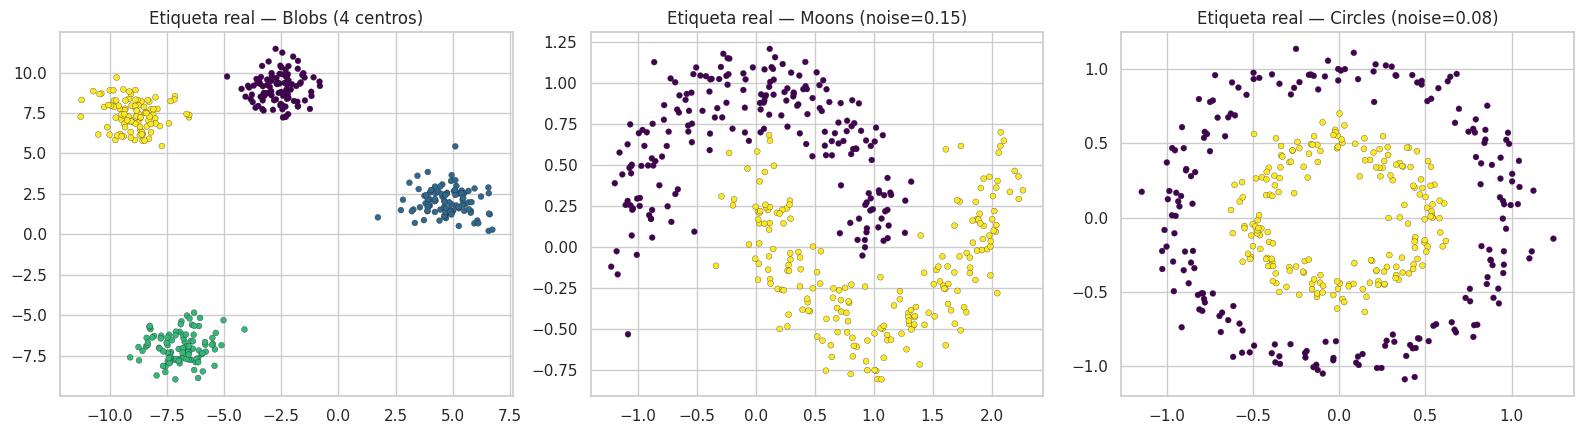

In [2]:
# 1. Tres datasets sintéticos
X_blobs, y_blobs = make_blobs(n_samples=400, centers=4, cluster_std=0.9, random_state=42)
X_moons, y_moons = make_moons(n_samples=400, noise=0.15, random_state=42)
X_circ, y_circ = make_circles(n_samples=400, noise=0.08, factor=0.5, random_state=42)
sets = {'Blobs (4 centros)': (X_blobs, y_blobs, 4), 'Moons (noise=0.15)': (X_moons, y_moons, 2), 'Circles (noise=0.08)': (X_circ, y_circ, 2)}

# 2. Visualización con la etiqueta real
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nombre, (X, y, k)) in zip(axes, sets.items()):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=18, edgecolor='k', linewidth=0.2)
    ax.set_title('Etiqueta real — %s' % nombre)
plt.tight_layout(); plt.show()

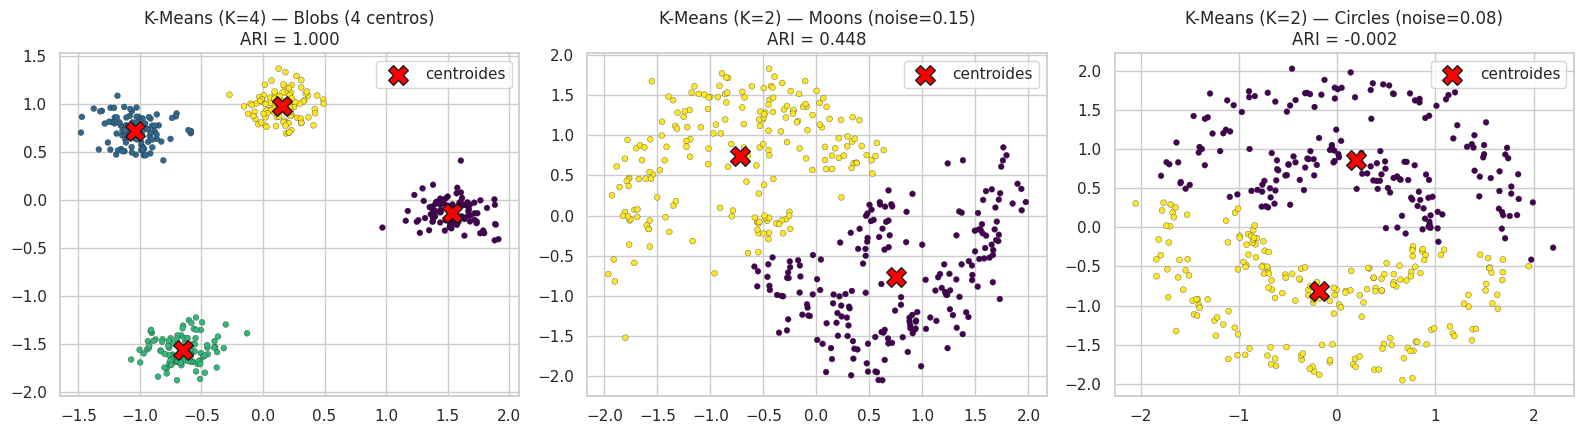

,K,ARI vs. etiqueta real,Silhouette
Dataset,,,
Blobs (4 centros),4,1.000,0.820
Moons (noise=0.15),2,0.448,0.477
Circles (noise=0.08),2,-0.002,0.353


In [3]:
# 3-4. Estandarizar y aplicar K-Means (K=4 para blobs, K=2 para moons/circles)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
filas = []
for ax, (nombre, (X, y, k)) in zip(axes, sets.items()):
    Xs = StandardScaler().fit_transform(X)
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    ax.scatter(Xs[:, 0], Xs[:, 1], c=km.labels_, cmap='viridis', s=18, edgecolor='k', linewidth=0.2)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='red', marker='X', s=200, edgecolor='k', label='centroides')
    ari = adjusted_rand_score(y, km.labels_)
    ax.set_title('K-Means (K=%d) — %s\nARI = %.3f' % (k, nombre, ari)); ax.legend(loc='best')
    filas.append({'Dataset': nombre, 'K': k, 'ARI vs. etiqueta real': ari, 'Silhouette': silhouette_score(Xs, km.labels_)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).set_index('Dataset').round(3))

#### Respuesta
| Dataset | K | ARI vs. etiqueta real | Silhouette |
|---|---|---|---|
| Blobs | 4 | **1.000** | 0.820 |
| Moons | 2 | 0.448 | 0.477 |
| Circles | 2 | −0.002 | 0.353 |

**¿En cuál funciona bien y en cuáles falla?** K-Means recupera los **blobs** a la perfección (ARI = 1), pero **falla en moons** (ARI 0.45: parte cada luna por la mitad) y **en circles** (ARI ≈ 0: equivale a asignar al azar).

**¿Por qué?** K-Means asigna cada punto al centroide más cercano, así que sus fronteras son siempre rectas (diagramas de Voronoi) y asume clusters **convexos, compactos y de tamaño parecido**. Los blobs cumplen eso; las lunas son formas curvas entrelazadas y los círculos son concéntricos (uno rodea al otro), de modo que ninguna partición por centroides puede separarlos. Para esas formas hacen falta métodos basados en densidad (DBSCAN) o conectividad. Ojo: el Silhouette (0.48 y 0.35) sigue pareciendo "aceptable" aun cuando la partición es incorrecta, porque premia clusters compactos y convexos; por eso conviene combinarlo con la inspección visual.

### Ejercicio 1.2 — K-Means manual paso a paso
**Dataset:** Crear 12 puntos 2D manualmente:
```python
X = np.array([[1,2],[1.5,1.8],[5,8],[8,8],[1,0.6],[9,11],
              [8,2],[10,2],[9,3],[3,7],[4,8],[3,5]])
```

**Tareas:**
1. Visualizar los 12 puntos con scatter plot
2. Inicializar 2 centroides en posiciones de tu elección
3. **Manualmente** (sin sklearn): calcular distancias, asignar clusters, recalcular centroides para 3 iteraciones
4. Comparar tu resultado manual con `KMeans(n_clusters=2)` de sklearn
5. Responder: ¿Cambiaron los clusters si hubieras elegido otros centroides iniciales?

**Entregable:** Pasos manuales documentados, comparación con sklearn.

#### Solución

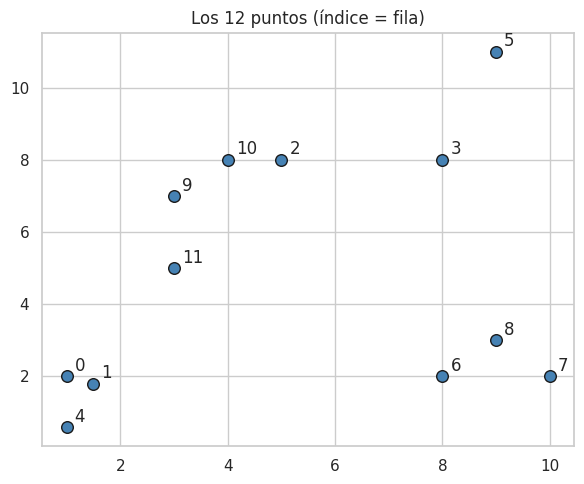

In [4]:
X12 = np.array([[1, 2], [1.5, 1.8], [5, 8], [8, 8], [1, 0.6], [9, 11],
                [8, 2], [10, 2], [9, 3], [3, 7], [4, 8], [3, 5]])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X12[:, 0], X12[:, 1], s=70, c='steelblue', edgecolor='k')
for i, (x, y) in enumerate(X12):
    ax.annotate(str(i), (x + 0.15, y + 0.15))
ax.set_title('Los 12 puntos (índice = fila)'); plt.tight_layout(); plt.show()

In [5]:
# 2-3. K-Means MANUAL (solo NumPy): distancias -> asignación -> nuevos centroides
def kmeans_manual(X, centroides, n_iter=3, verbose=True):
    C = np.array(centroides, dtype=float)
    historial = [C.copy()]
    for it in range(1, n_iter + 1):
        # (a) distancia euclídea de cada punto a cada centroide
        D = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        # (b) cada punto se asigna al centroide más cercano
        etiquetas = D.argmin(axis=1)
        # (c) cada centroide pasa a ser la media de sus puntos
        C_nuevo = np.array([X[etiquetas == k].mean(axis=0) if (etiquetas == k).any() else C[k] for k in range(len(C))])
        if verbose:
            print('=' * 70)
            print('ITERACIÓN %d' % it)
            print('Centroides de entrada:', C.round(3).tolist())
            tabla = pd.DataFrame(D, columns=['d(C%d)' % (k + 1) for k in range(len(C))]).round(3)
            tabla['cluster'] = etiquetas + 1
            display(tabla.T.rename(columns=lambda i: 'p%d' % i))
            print('Nuevos centroides:', C_nuevo.round(3).tolist())
        movimiento = np.abs(C_nuevo - C).max()
        C = C_nuevo; historial.append(C.copy())
        if movimiento < 1e-9:
            if verbose: print('\n>>> Convergió en la iteración %d (los centroides ya no se mueven).' % it)
            break
    return C, etiquetas, historial

c_ini = [[1, 1], [10, 10]]                    # centroides iniciales elegidos (sin empates de distancia)
C_fin, lab_fin, hist = kmeans_manual(X12, c_ini, n_iter=3)

ITERACIÓN 1
Centroides de entrada: [[1.0, 1.0], [10.0, 10.0]]


,p0,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11
d(C1),1.000,0.943,8.062,9.899,0.400,12.806,7.071,9.055,8.246,6.325,7.616,4.472
d(C2),12.042,11.811,5.385,2.828,13.014,1.414,8.246,8.000,7.071,7.616,6.325,8.602
cluster,1.000,1.000,2.000,2.000,1.000,2.000,1.000,2.000,2.000,1.000,2.000,1.000


Nuevos centroides: [[2.917, 3.067], [7.5, 6.667]]
ITERACIÓN 2
Centroides de entrada: [[2.917, 3.067], [7.5, 6.667]]


,p0,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11
d(C1),2.193,1.900,5.355,7.084,3.124,9.997,5.194,7.163,6.084,3.934,5.051,1.935
d(C2),8.002,7.726,2.833,1.424,8.891,4.586,4.693,5.294,3.962,4.512,3.745,4.799
cluster,1.000,1.000,2.000,2.000,1.000,2.000,2.000,2.000,2.000,1.000,2.000,1.000


Nuevos centroides: [[1.9, 3.28], [7.571, 6.0]]
ITERACIÓN 3
Centroides de entrada: [[1.9, 3.28], [7.571, 6.0]]


,p0,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11
d(C1),1.565,1.533,5.647,7.713,2.827,10.488,6.233,8.201,7.106,3.879,5.166,2.042
d(C2),7.693,7.383,3.258,2.045,8.506,5.200,4.023,4.680,3.323,4.680,4.093,4.680
cluster,1.000,1.000,2.000,2.000,1.000,2.000,2.000,2.000,2.000,1.000,2.000,1.000


Nuevos centroides: [[1.9, 3.28], [7.571, 6.0]]

>>> Convergió en la iteración 3 (los centroides ya no se mueven).


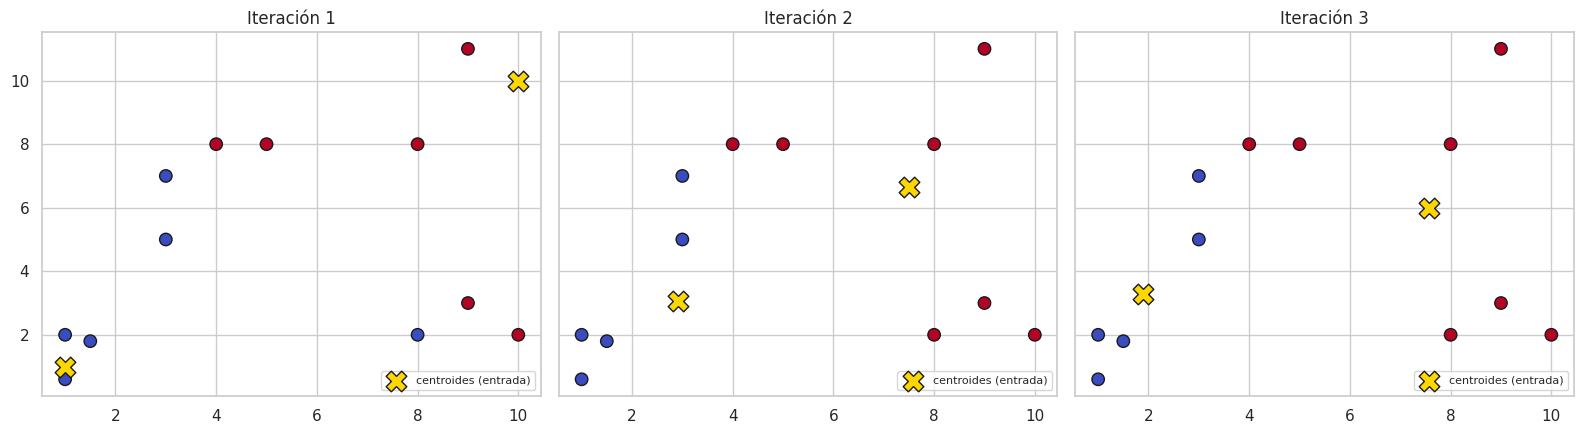

In [6]:
# Visualización de las 3 iteraciones
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
C = np.array(c_ini, float)
for it, ax in enumerate(axes, start=1):
    D = np.sqrt(((X12[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)); lab = D.argmin(axis=1)
    ax.scatter(X12[:, 0], X12[:, 1], c=lab, cmap='coolwarm', s=80, edgecolor='k')
    ax.scatter(C[:, 0], C[:, 1], marker='X', s=220, c='gold', edgecolor='k', label='centroides (entrada)')
    ax.set_title('Iteración %d' % it); ax.legend(loc='lower right', fontsize=8)
    C = np.array([X12[lab == k].mean(axis=0) for k in range(2)])
plt.tight_layout(); plt.show()

In [7]:
# 4. Comparación con scikit-learn
km_sk = KMeans(n_clusters=2, init=np.array(c_ini, float), n_init=1).fit(X12)          # mismos centroides iniciales
km_sk10 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X12)                     # configuración por defecto
print('Centroides manual   :', C_fin.round(3).tolist())
print('Centroides sklearn  :', km_sk.cluster_centers_.round(3).tolist())
print('Etiquetas idénticas (misma partición) -> ARI manual vs sklearn = %.3f' % adjusted_rand_score(lab_fin, km_sk.labels_))
print('Inercia manual: %.3f | sklearn: %.3f' % (((X12 - C_fin[lab_fin]) ** 2).sum(), km_sk.inertia_))
print('sklearn con n_init=10 (inicialización k-means++) -> centroides %s | inercia %.3f | ARI vs manual = %.3f' %
      (km_sk10.cluster_centers_.round(3).tolist(), km_sk10.inertia_, adjusted_rand_score(lab_fin, km_sk10.labels_)))

Centroides manual   : [[1.9, 3.28], [7.571, 6.0]]
Centroides sklearn  : [[1.9, 3.28], [7.571, 6.0]]
Etiquetas idénticas (misma partición) -> ARI manual vs sklearn = 1.000
Inercia manual: 139.722 | sklearn: 139.722
sklearn con n_init=10 (inicialización k-means++) -> centroides [[1.625, 2.35], [7.0, 6.125]] | inercia 140.073 | ARI vs manual = 0.667


In [8]:
# 5. ¿Cambia el resultado con otros centroides iniciales?
inicios = {'A: [1,1] y [10,10]': [[1, 1], [9, 9]],
           'B: [1,2] y [1.5,1.8] (ambos en la izquierda)': [[1, 2], [1.5, 1.8]],
           'C: [3,5] y [8,2]': [[3, 5], [8, 2]],
           'D: [5,8] y [9,3]': [[5, 8], [9, 3]]}
filas, etiquetas_por_inicio = [], {}
for nombre, c0 in inicios.items():
    C, lab, _ = kmeans_manual(X12, c0, n_iter=20, verbose=False)
    inercia = ((X12 - C[lab]) ** 2).sum()
    etiquetas_por_inicio[nombre] = lab
    filas.append({'Centroides iniciales': nombre, 'Centroides finales': str(C.round(2).tolist()), 'Tamaños': str(np.bincount(lab).tolist()),
                  'Inercia': round(inercia, 2), 'ARI vs. inicio A': round(adjusted_rand_score(etiquetas_por_inicio['A: [1,1] y [10,10]'], lab), 3)})
display(pd.DataFrame(filas).set_index('Centroides iniciales'))

,Centroides finales,Tamaños,Inercia,ARI vs. inicio A
Centroides iniciales,,,,
"A: [1,1] y [10,10]","[[1.9, 3.28], [7.57, 6.0]]","[5, 7]",139.72,1.000
"B: [1,2] y [1.5,1.8] (ambos en la izquierda)","[[1.9, 3.28], [7.57, 6.0]]","[5, 7]",139.72,1.000
"C: [3,5] y [8,2]","[[3.94, 5.71], [9.0, 2.33]]","[9, 3]",171.94,0.041
"D: [5,8] y [9,3]","[[4.31, 6.35], [7.0, 1.9]]","[8, 4]",183.05,-0.059


#### Respuesta
**Resultado del cálculo manual** (centroides iniciales (1,1) y (10,10)): en 3 iteraciones los centroides pasan de (1,1),(10,10) → (2.917, 3.067),(7.5, 6.667) → (1.9, 3.28),(7.571, 6.0), y en la iteración 3 ya no se mueven (convergencia). Los clusters quedan con 5 y 7 puntos.

**Comparación con scikit-learn:** al darle los mismos centroides iniciales, `KMeans` da exactamente el mismo resultado (centroides idénticos, ARI = 1.0, inercia 139.722). Con su configuración por defecto (`n_init=10`, inicialización k-means++) encuentra otra solución estable, con centroides (1.625, 2.35) y (7.0, 6.125) e inercia 140.073, que solo difiere en un punto, el (3, 7) (ARI = 0.667).

**¿Cambian los clusters con otros centroides iniciales?** **Sí, puede cambiar**: con los inicios A y B (incluso con los dos centroides en la esquina izquierda) se llega a la misma partición (inercia 139.72), pero con C = (3,5),(8,2) se obtiene otra (9 y 3 puntos, inercia 171.94) y con D = (5,8),(9,3) otra distinta (8 y 4 puntos, inercia 183.05); su ARI contra la solución A es ≈ 0. K-Means solo garantiza llegar a un **mínimo local** que depende de la inicialización; por eso se usan k-means++ y varias inicializaciones (`n_init`) y se conserva la de menor inercia.

### Ejercicio 1.3 — Importancia de la estandarización
**Dataset:** Crear datos con escalas muy diferentes:
```python
np.random.seed(42)
ingresos = np.random.normal(50000, 15000, 200)  # Soles
edad = np.random.normal(35, 10, 200)  # Años
X = np.column_stack([ingresos, edad])
```

**Tareas:**
1. Aplicar K-Means (K=3) SIN estandarizar y visualizar
2. Aplicar K-Means (K=3) CON StandardScaler y visualizar
3. Mostrar ambos resultados lado a lado
4. Calcular el Silhouette Score para ambos casos
5. Responder: ¿Por qué los resultados son tan diferentes? ¿Cuál es más razonable?

**Entregable:** Gráficos comparativos y explicación.

#### Solución

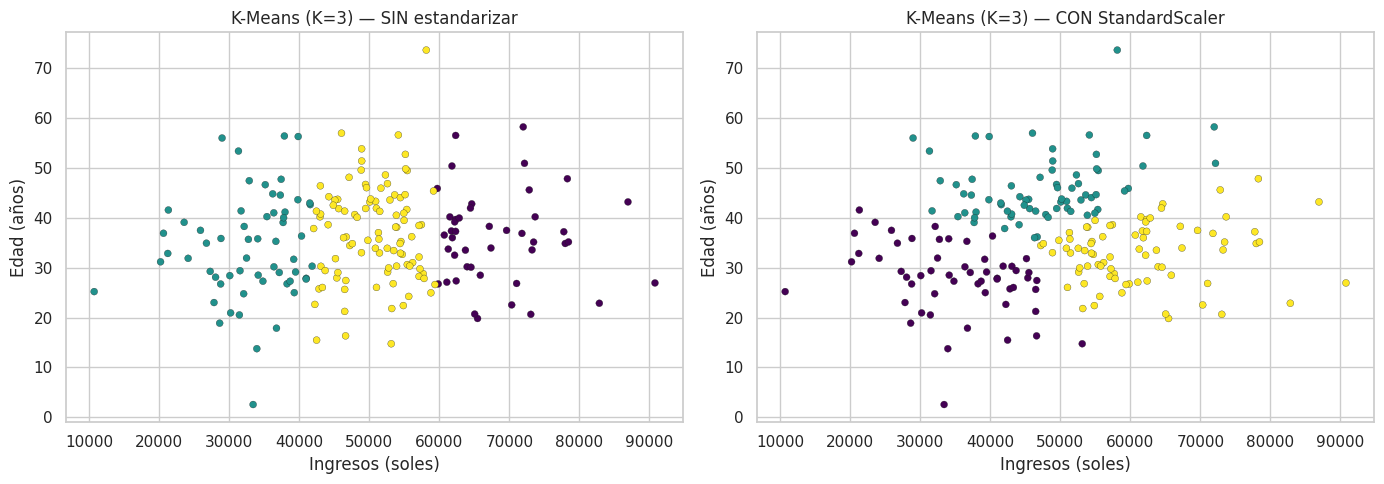

In [9]:
np.random.seed(42)
ingresos = np.random.normal(50000, 15000, 200)  # Soles
edad = np.random.normal(35, 10, 200)  # Años
X13 = np.column_stack([ingresos, edad])

# 1-2. K-Means (K=3) sin y con estandarización
km_raw = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X13)
Xs13 = StandardScaler().fit_transform(X13)
km_std = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xs13)

# 3. Resultados lado a lado (ambos graficados en las unidades originales para poder compararlos)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, tit in zip(axes, [km_raw.labels_, km_std.labels_], ['SIN estandarizar', 'CON StandardScaler']):
    ax.scatter(X13[:, 0], X13[:, 1], c=lab, cmap='viridis', s=25, edgecolor='k', linewidth=0.2)
    ax.set_xlabel('Ingresos (soles)'); ax.set_ylabel('Edad (años)'); ax.set_title('K-Means (K=3) — %s' % tit)
plt.tight_layout(); plt.show()

In [10]:
# 4. Silhouette Score
sil_raw_espacio_raw = silhouette_score(X13, km_raw.labels_)
sil_std_espacio_std = silhouette_score(Xs13, km_std.labels_)
sil_raw_en_std = silhouette_score(Xs13, km_raw.labels_)      # evalúa AMBAS particiones en el mismo espacio (estandarizado)
print('Silhouette (cada una en su propio espacio): sin estandarizar = %.3f | estandarizado = %.3f' % (sil_raw_espacio_raw, sil_std_espacio_std))
print('Silhouette de ambas particiones en el espacio estandarizado: sin estandarizar = %.3f | estandarizado = %.3f' % (sil_raw_en_std, sil_std_espacio_std))
print('\nRango de cada variable (qué variable domina la distancia en bruto):')
print('  ingresos: std = %.0f  |  edad: std = %.1f' % (X13[:, 0].std(), X13[:, 1].std()))
def eta2(x, lab):
    # fracción de la varianza de x explicada por los clusters (suma de cuadrados entre grupos / total)
    tot = ((x - x.mean()) ** 2).sum()
    ent = sum(((lab == c).sum()) * (x[lab == c].mean() - x.mean()) ** 2 for c in np.unique(lab))
    return ent / tot
print('\nVarianza de cada variable explicada por los clusters (η², 1 = los clusters la determinan por completo):')
print(pd.DataFrame({'SIN estandarizar': [eta2(X13[:, 0], km_raw.labels_), eta2(X13[:, 1], km_raw.labels_)],
                    'CON estandarizar': [eta2(X13[:, 0], km_std.labels_), eta2(X13[:, 1], km_std.labels_)]},
                   index=['ingresos', 'edad']).round(3).to_string())

Silhouette (cada una en su propio espacio): sin estandarizar = 0.544 | estandarizado = 0.376
Silhouette de ambas particiones en el espacio estandarizado: sin estandarizar = 0.232 | estandarizado = 0.376

Rango de cada variable (qué variable domina la distancia en bruto):
  ingresos: std = 13930  |  edad: std = 9.8

Varianza de cada variable explicada por los clusters (η², 1 = los clusters la determinan por completo):
          SIN estandarizar  CON estandarizar
ingresos             0.816              0.59
edad                 0.016              0.57


#### Respuesta
- **Sin estandarizar:** los ingresos (desviación ≈ 13 930 soles) pesan ≈ 1 400 veces más que la edad (≈ 9.8 años) en la distancia euclídea, así que K-Means forma bandas verticales por ingreso y **ignora la edad**: los clusters explican el 81.6 % de la varianza del ingreso y solo el 1.6 % de la de la edad.
- **Estandarizando:** ambas variables aportan por igual (59 % y 57 %), y los clusters son regiones que combinan ingreso y edad.
- **Silhouette:** 0.544 sin estandarizar vs. 0.376 estandarizado. El número más alto del caso sin estandarizar es **engañoso**: se mide en un espacio distinto (prácticamente unidimensional). Si se evalúan las dos particiones en el mismo espacio estandarizado, la partición sin escalar baja a 0.232 y la estandarizada (0.376) es mejor.
- **¿Cuál es más razonable?** La estandarizada, porque trata las variables en pie de igualdad. (Además, como ingresos y edad se generaron como normales independientes, los datos forman una sola nube sin clusters naturales; el ejercicio sirve para ver el efecto de la escala.)

---
## Nivel 2: Intermedio (Aplicación de algoritmos)

### Ejercicio 2.1 — Selección de K con Iris
**Dataset:** `sklearn.datasets.load_iris()` (sin usar las etiquetas)

**Tareas:**
1. Estandarizar los datos
2. Aplicar el Método del Codo (K=2 a 10)
3. Calcular el Silhouette Score para K=2 a 10
4. Graficar ambas métricas
5. Seleccionar K óptimo y aplicar K-Means
6. Comparar con las etiquetas reales: calcular ARI y NMI
7. Visualizar clusters con PCA (2D) y colorear: una vez por cluster, una vez por etiqueta real
8. Responder: ¿El clustering encontró las 3 especies de Iris?

**Entregable:** Gráficos, métricas y análisis comparativo.

#### Solución

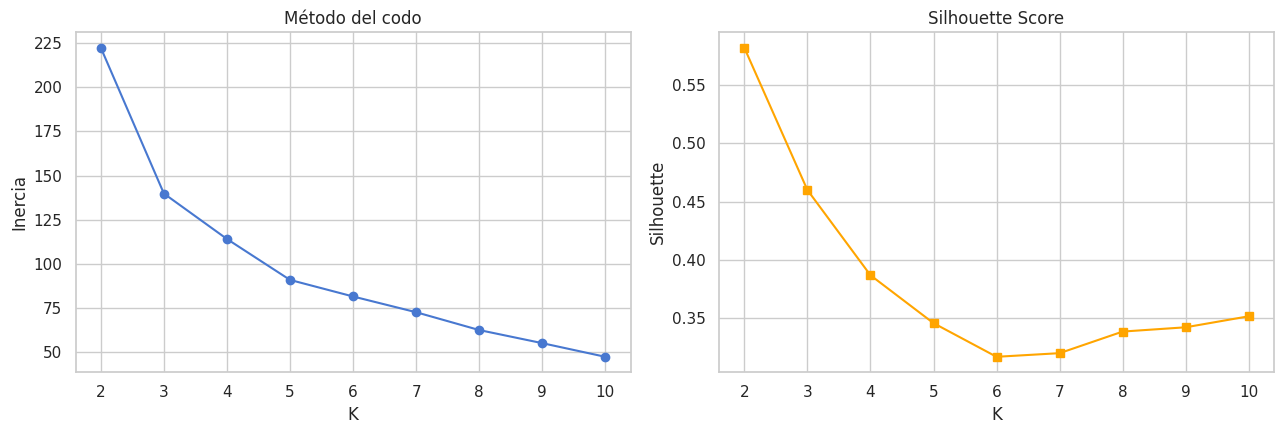

K,2,3,4,5,6,7,8,9,10
Inercia,222.362,139.82,114.093,90.928,81.544,72.631,62.541,55.119,47.391
Silhouette,0.582,0.46,0.387,0.346,0.317,0.320,0.339,0.342,0.352


K con mayor silhouette: 2


In [11]:
iris = datasets.load_iris()
Xi, yi = iris.data, iris.target                 # yi NO se usa para agrupar, solo para comparar al final
Xi_s = StandardScaler().fit_transform(Xi)

# 2-3. Método del codo y Silhouette para K = 2..10
Ks = range(2, 11)
inercias, sils = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xi_s)
    inercias.append(km.inertia_); sils.append(silhouette_score(Xi_s, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(Ks), inercias, 'o-'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inercia'); axes[0].set_title('Método del codo')
axes[1].plot(list(Ks), sils, 's-', color='orange'); axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette'); axes[1].set_title('Silhouette Score')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'K': list(Ks), 'Inercia': inercias, 'Silhouette': sils}).round(3).set_index('K').T)
K_sil = list(Ks)[int(np.argmax(sils))]
print('K con mayor silhouette: %d' % K_sil)

In [12]:
# 5-6. K-Means con K óptimo (silhouette) y con K = 3 (nº de especies); comparación con las etiquetas reales
filas, modelos = [], {}
for k in sorted({K_sil, 3}):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xi_s)
    modelos[k] = km
    filas.append({'K': k, 'Silhouette': silhouette_score(Xi_s, km.labels_),
                  'ARI': adjusted_rand_score(yi, km.labels_), 'NMI': normalized_mutual_info_score(yi, km.labels_)})
display(pd.DataFrame(filas).set_index('K').round(3))
print(pd.crosstab(pd.Series(yi, name='especie real').map(dict(enumerate(iris.target_names))), pd.Series(modelos[3].labels_, name='cluster (K=3)')))

,Silhouette,ARI,NMI
K,,,
2,0.582,0.568,0.734
3,0.460,0.620,0.659


cluster (K=3)   0   1   2
especie real             
setosa          0  50   0
versicolor     39   0  11
virginica      14   0  36


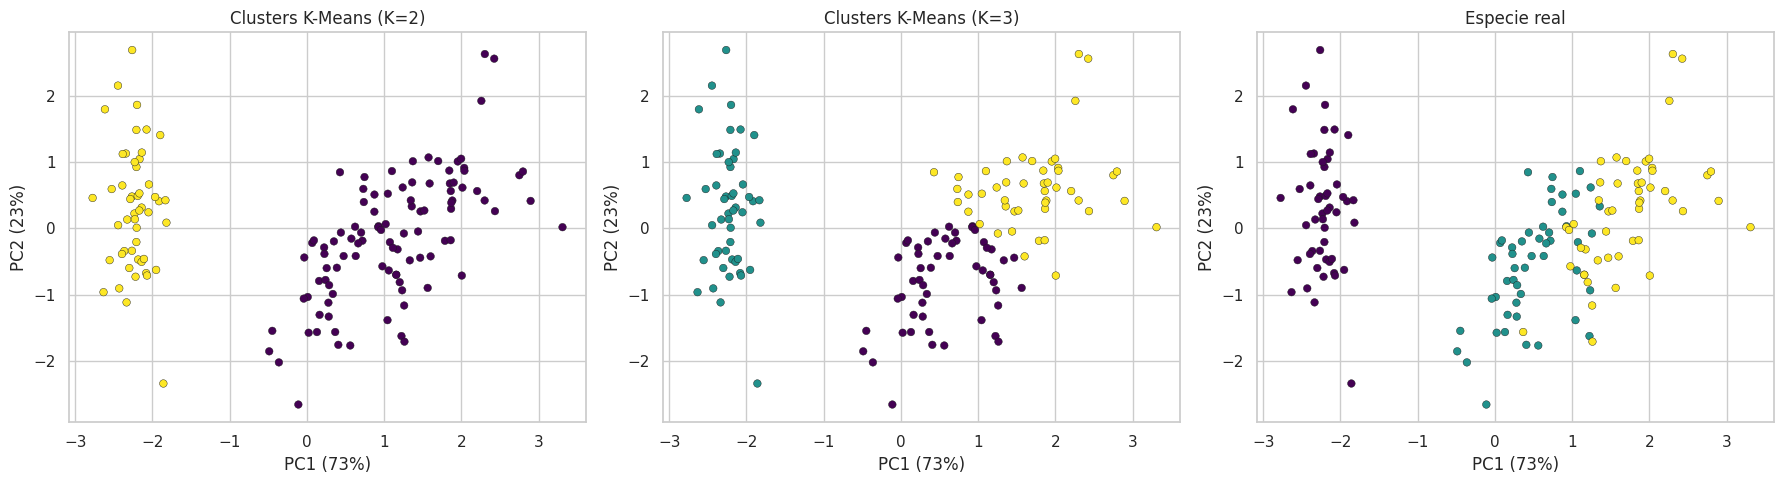

In [13]:
# 7. Visualización con PCA (2D): por cluster y por etiqueta real
pca = PCA(n_components=2).fit(Xi_s); Z = pca.transform(Xi_s)
paneles = [('Clusters K-Means (K=%d)' % K_sil, modelos[K_sil].labels_)] if K_sil != 3 else []
paneles += [('Clusters K-Means (K=3)', modelos[3].labels_), ('Especie real', yi)]
fig, axes = plt.subplots(1, len(paneles), figsize=(6 * len(paneles), 5))
for ax, (tit, lab) in zip(axes, paneles):
    ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap='viridis', s=30, edgecolor='k', linewidth=0.3)
    ax.set_title(tit); ax.set_xlabel('PC1 (%.0f%%)' % (100 * pca.explained_variance_ratio_[0])); ax.set_ylabel('PC2 (%.0f%%)' % (100 * pca.explained_variance_ratio_[1]))
plt.tight_layout(); plt.show()

#### Respuesta
- **Selección de K:** el Silhouette es máximo en **K = 2** (0.582) y cae a 0.460 en K = 3; la curva del codo no tiene un "codo" nítido (la inercia baja de 222 a 140 entre K = 2 y 3 y luego decrece suavemente). El K = 2 refleja que *setosa* está muy separada y *versicolor* y *virginica* se solapan; por conocimiento del dominio se compara también K = 3.
- **Comparación con las etiquetas reales:** K = 2 → ARI 0.568, NMI 0.734; K = 3 → ARI 0.620, NMI 0.659.
- **¿Encontró las 3 especies?** Solo en parte. *Setosa* se recupera perfectamente (los 50 ejemplares en un único cluster), pero *versicolor* y *virginica* se mezclan: el cluster 0 tiene 39 versicolor + 14 virginica y el cluster 2 tiene 11 versicolor + 36 virginica. El clustering no supervisado separa bien la estructura "setosa vs. resto", pero la frontera entre las otras dos especies no es recuperable solo con las medidas (en el PCA se ve el solapamiento).

### Ejercicio 2.2 — DBSCAN: efecto de eps y min_samples
**Dataset:** `make_moons(n_samples=500, noise=0.1)`

**Tareas:**
1. Crear el gráfico de K-distancias para estimar eps
2. Probar DBSCAN con eps = [0.05, 0.1, 0.2, 0.3, 0.5] y min_samples=5
3. Para cada configuración: reportar número de clusters, puntos de ruido y Silhouette Score
4. Crear una cuadrícula de gráficos (5 columnas) mostrando los clusters
5. Repetir con eps=0.2 y min_samples = [2, 5, 10, 15, 20]
6. Responder: ¿Cómo afectan eps y min_samples al resultado? ¿Cuál es la mejor combinación?

**Entregable:** Cuadrículas de gráficos, tabla de resultados y análisis.

#### Solución

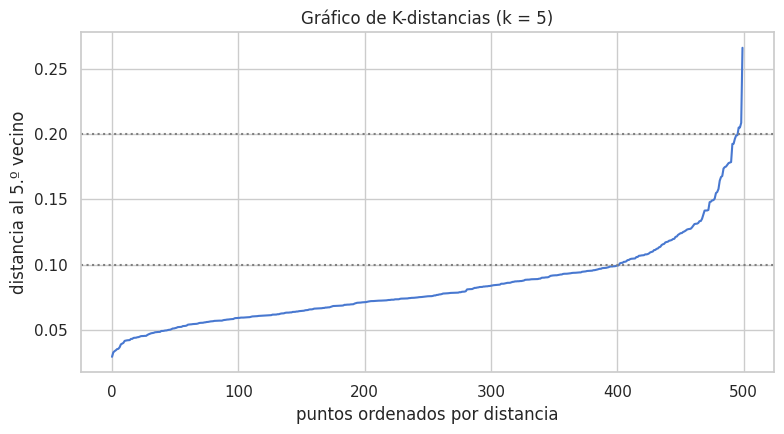

Percentiles de la distancia al 5.º vecino: p50 = 0.076 | p90 = 0.123 | p95 = 0.148 | p99 = 0.199


In [14]:
X22, y22 = make_moons(n_samples=500, noise=0.1, random_state=42)

# 1. Gráfico de K-distancias (k = min_samples = 5): la "rodilla" sugiere eps
k_dist = 5
nn = NearestNeighbors(n_neighbors=k_dist).fit(X22)
dist, _ = nn.kneighbors(X22)
kd = np.sort(dist[:, -1])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kd); ax.set_xlabel('puntos ordenados por distancia'); ax.set_ylabel('distancia al %d.º vecino' % k_dist)
for e in [0.1, 0.2]: ax.axhline(e, color='gray', linestyle=':')
ax.set_title('Gráfico de K-distancias (k = %d)' % k_dist); plt.tight_layout(); plt.show()
print('Percentiles de la distancia al %d.º vecino: p50 = %.3f | p90 = %.3f | p95 = %.3f | p99 = %.3f' % (k_dist, *np.quantile(kd, [0.5, 0.9, 0.95, 0.99])))

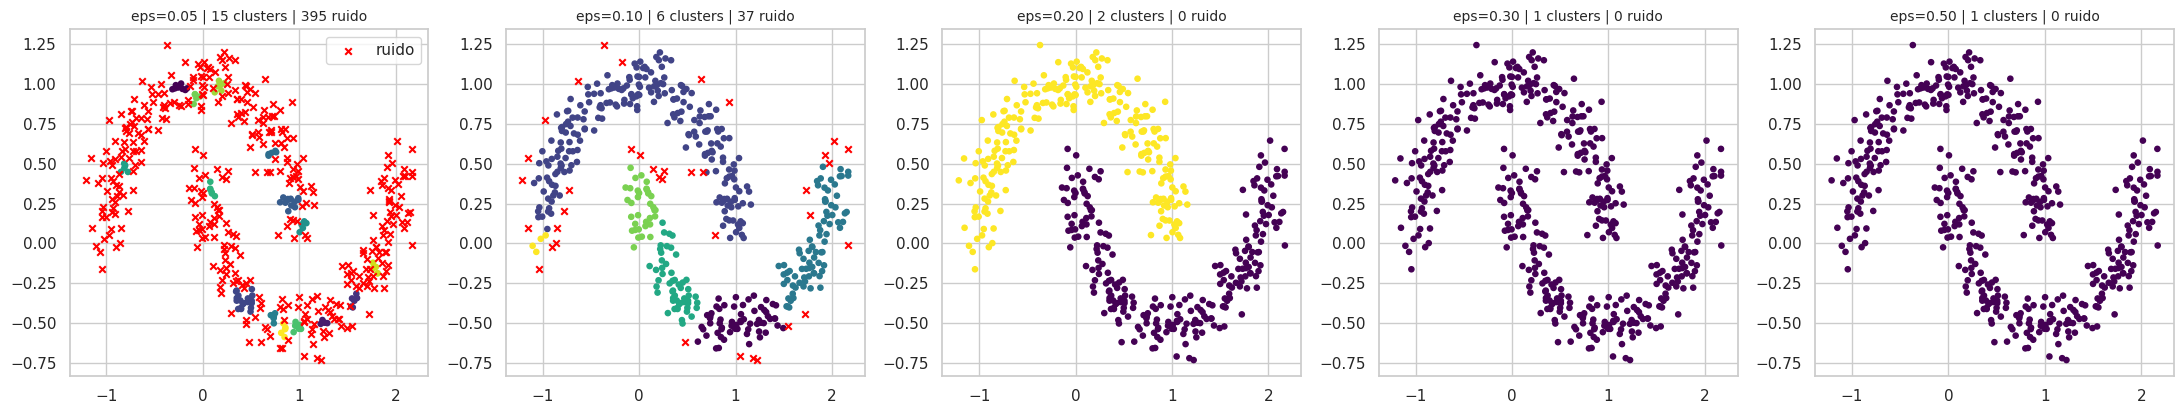

,min_samples,clusters,ruido,Silhouette,ARI
eps,,,,,
0.05,5,15,395,0.737,0.007
0.10,5,6,37,0.199,0.530
0.20,5,2,0,0.327,1.000
0.30,5,1,0,NaN,0.000
0.50,5,1,0,NaN,0.000


In [15]:
def evaluar_dbscan(X, y, eps, ms):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    ruido = int((lab == -1).sum())
    mask = lab != -1
    sil = silhouette_score(X[mask], lab[mask]) if n_cl >= 2 and mask.sum() > n_cl else np.nan
    return lab, {'eps': eps, 'min_samples': ms, 'clusters': n_cl, 'ruido': ruido, 'Silhouette': sil, 'ARI': adjusted_rand_score(y, lab)}

# 2-4. Variar eps (min_samples = 5)
eps_lista = [0.05, 0.1, 0.2, 0.3, 0.5]
filas, labs = [], []
for e in eps_lista:
    lab, r = evaluar_dbscan(X22, y22, e, 5); filas.append(r); labs.append(lab)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.3))
for ax, lab, r in zip(axes, labs, filas):
    ax.scatter(X22[lab != -1, 0], X22[lab != -1, 1], c=lab[lab != -1], cmap='viridis', s=14)
    ax.scatter(X22[lab == -1, 0], X22[lab == -1, 1], c='red', marker='x', s=22, label='ruido')
    ax.set_title('eps=%.2f | %d clusters | %d ruido' % (r['eps'], r['clusters'], r['ruido']), fontsize=10)
axes[0].legend(); plt.tight_layout(); plt.show()
tabla_eps = pd.DataFrame(filas).set_index('eps'); display(tabla_eps.round(3))

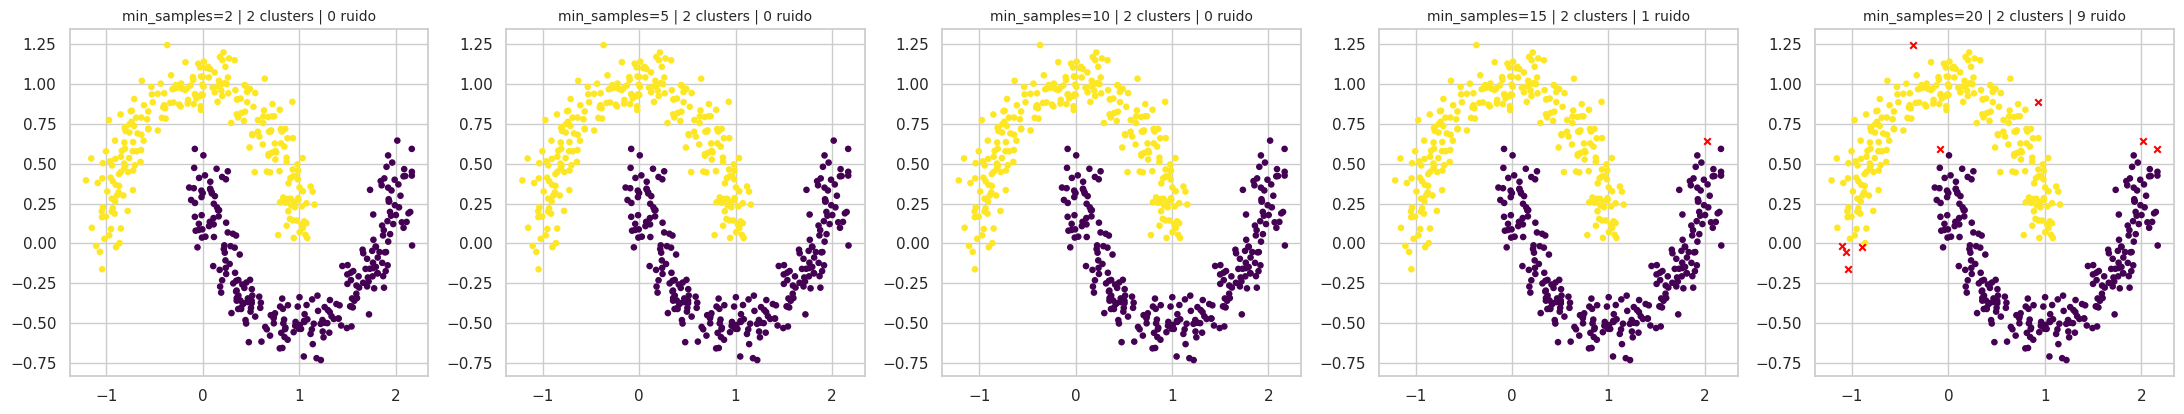

,eps,clusters,ruido,Silhouette,ARI
min_samples,,,,,
2,0.2,2,0,0.327,1.000
5,0.2,2,0,0.327,1.000
10,0.2,2,0,0.327,1.000
15,0.2,2,1,0.328,0.996
20,0.2,2,9,0.331,0.964


In [16]:
# 5. Variar min_samples (eps = 0.2)
ms_lista = [2, 5, 10, 15, 20]
filas, labs = [], []
for m in ms_lista:
    lab, r = evaluar_dbscan(X22, y22, 0.2, m); filas.append(r); labs.append(lab)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.3))
for ax, lab, r in zip(axes, labs, filas):
    ax.scatter(X22[lab != -1, 0], X22[lab != -1, 1], c=lab[lab != -1], cmap='viridis', s=14)
    ax.scatter(X22[lab == -1, 0], X22[lab == -1, 1], c='red', marker='x', s=22)
    ax.set_title('min_samples=%d | %d clusters | %d ruido' % (r['min_samples'], r['clusters'], r['ruido']), fontsize=10)
plt.tight_layout(); plt.show()
tabla_ms = pd.DataFrame(filas).set_index('min_samples'); display(tabla_ms.round(3))

#### Respuesta
| eps (min_samples = 5) | Clusters | Ruido | ARI |
|---|---|---|---|
| 0.05 | 15 | 395 | 0.007 |
| 0.10 | 6 | 37 | 0.530 |
| **0.20** | **2** | **0** | **1.000** |
| 0.30 | 1 | 0 | 0.000 |
| 0.50 | 1 | 0 | 0.000 |

Con eps = 0.2 y distintos `min_samples`: 2, 5 y 10 → ARI 1.000 (0 ruido); 15 → 1 punto de ruido (ARI 0.996); 20 → 9 puntos de ruido (ARI 0.964).

**¿Cómo afectan eps y min_samples?** `eps` es el parámetro decisivo: demasiado pequeño (0.05) casi todo es ruido y aparecen microclusters; demasiado grande (≥ 0.3) las dos lunas se "conectan" y se funden en un solo cluster. `min_samples` modula la exigencia de densidad: valores altos (15–20) empiezan a etiquetar como ruido puntos de los bordes. El gráfico de K-distancias ayuda a elegir `eps`: sus percentiles 90–99 están entre 0.12 y 0.20, y la rodilla coincide con el valor que funciona (0.2).

**Mejor combinación:** **eps = 0.2 con min_samples entre 5 y 10** (recupera las dos lunas sin ruido). *Cuidado con el Silhouette:* para eps = 0.05 vale 0.737 (el más alto de la tabla) a pesar de ser la peor partición, porque solo se calcula sobre los pocos puntos no ruidosos; con formas no convexas no es una métrica fiable y conviene mirar los gráficos.

### Ejercicio 2.3 — Clustering Jerárquico: comparación de linkages
**Dataset:** `sklearn.datasets.load_wine()` (sin etiquetas)

**Tareas:**
1. Estandarizar los datos
2. Crear dendrogramas con 4 métodos de linkage: single, complete, average, ward
3. Aplicar clustering aglomerativo con K=3 para cada linkage
4. Calcular Silhouette Score y ARI para cada uno
5. Visualizar con PCA (2D) los 4 resultados
6. Responder: ¿Qué linkage produce los mejores clusters? ¿Por qué ward es el predeterminado?

**Entregable:** 4 dendrogramas, tabla comparativa, gráficos PCA.

#### Solución

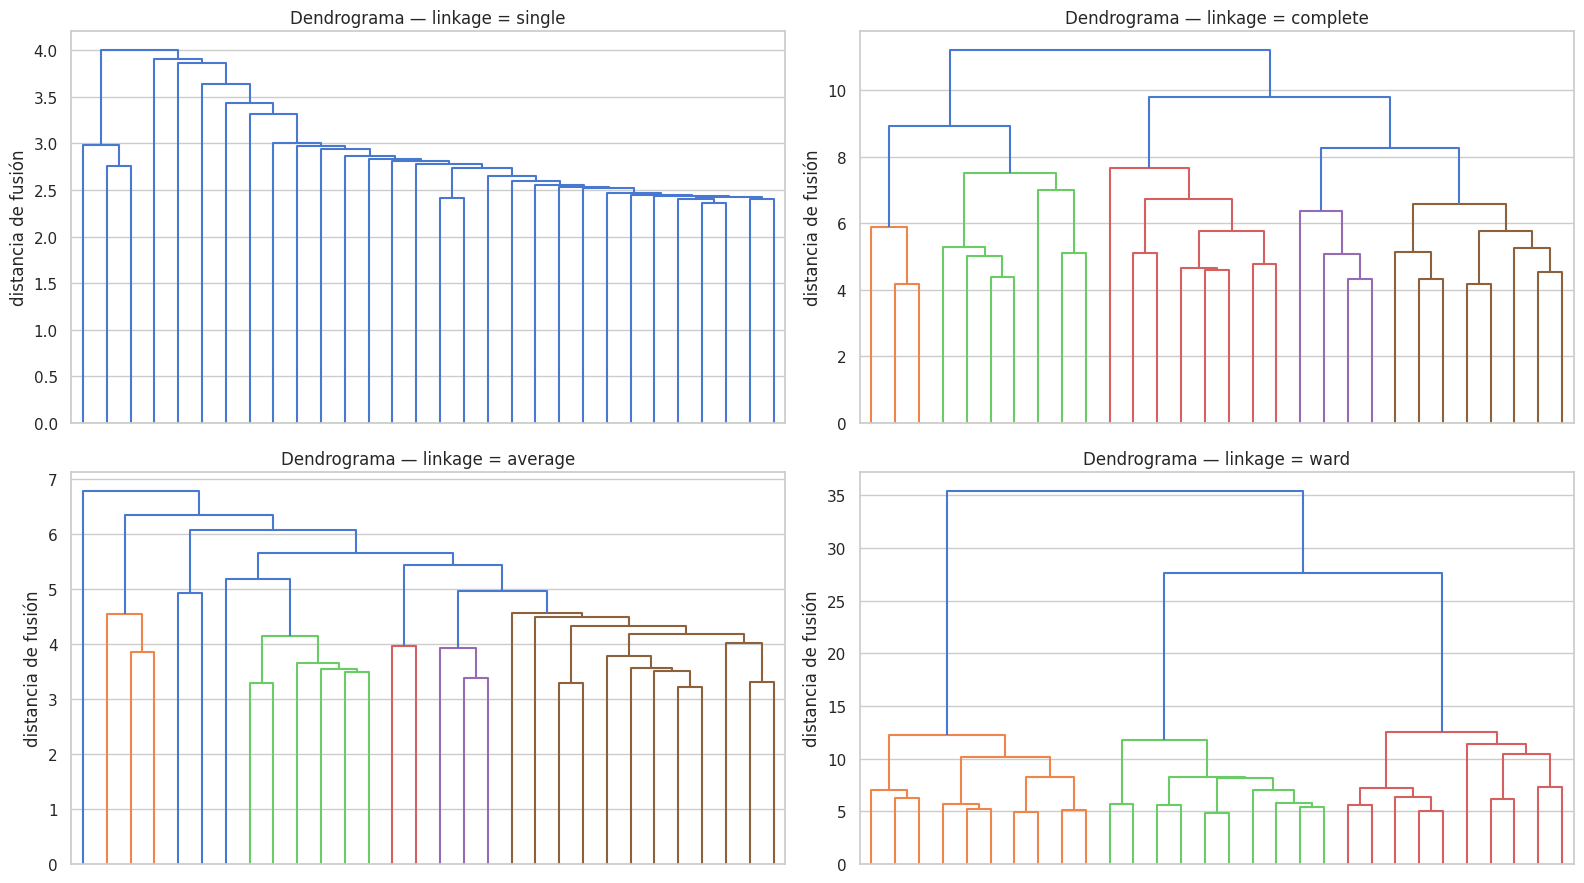

In [17]:
wine = datasets.load_wine()
Xw, yw = wine.data, wine.target
Xw_s = StandardScaler().fit_transform(Xw)

# 2. Dendrogramas con 4 métodos de linkage
metodos = ['single', 'complete', 'average', 'ward']
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, met in zip(axes.ravel(), metodos):
    Z = linkage(Xw_s, method=met)
    dendrogram(Z, truncate_mode='lastp', p=30, ax=ax, no_labels=True, color_threshold=0 if met == 'single' else None)
    ax.set_title('Dendrograma — linkage = %s' % met); ax.set_ylabel('distancia de fusión')
plt.tight_layout(); plt.show()

,Silhouette,ARI,tamaños de cluster
linkage,,,
single,0.183,-0.007,"[174, 3, 1]"
complete,0.204,0.577,"[69, 58, 51]"
average,0.158,-0.005,"[174, 3, 1]"
ward,0.277,0.790,"[64, 58, 56]"


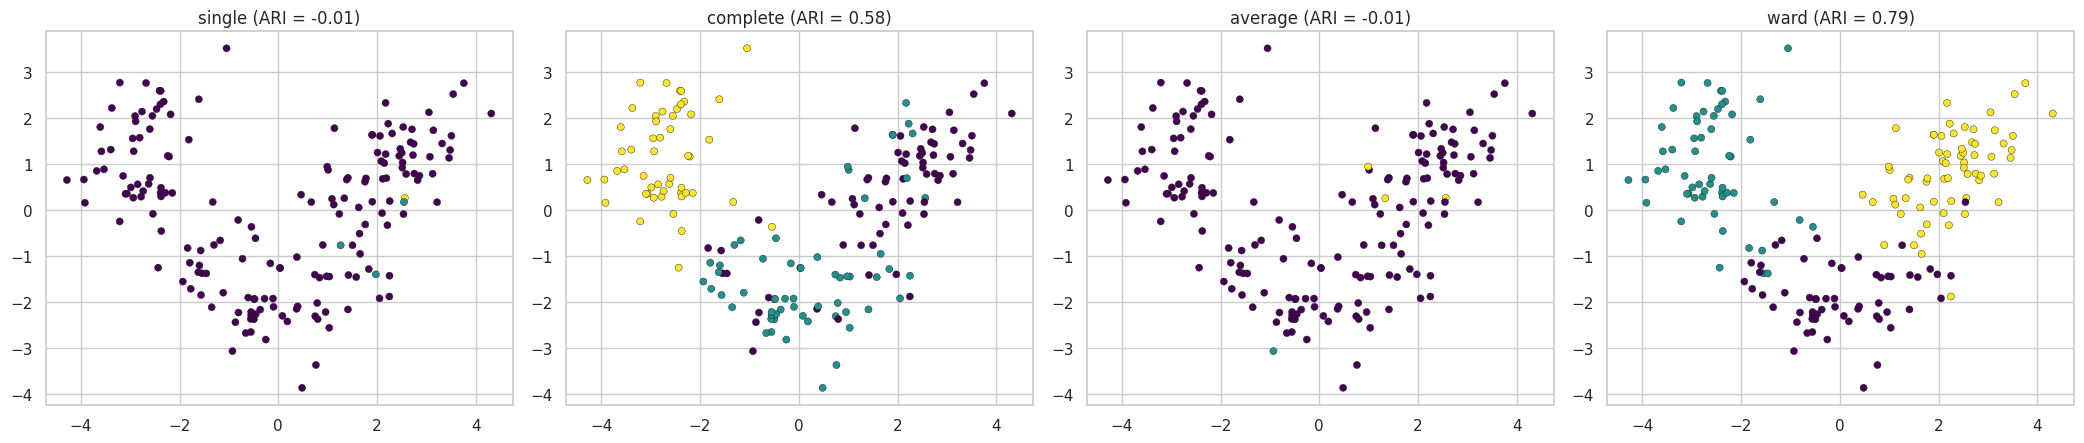

In [18]:
# 3-4. Clustering aglomerativo (K=3) con cada linkage: Silhouette y ARI
filas, etiquetas = [], {}
for met in metodos:
    lab = AgglomerativeClustering(n_clusters=3, linkage=met).fit_predict(Xw_s)
    etiquetas[met] = lab
    filas.append({'linkage': met, 'Silhouette': silhouette_score(Xw_s, lab), 'ARI': adjusted_rand_score(yw, lab),
                  'tamaños de cluster': str(sorted(np.bincount(lab).tolist(), reverse=True))})
tabla_link = pd.DataFrame(filas).set_index('linkage'); display(tabla_link.round(3))

# 5. PCA (2D) de los 4 resultados
Zw = PCA(n_components=2).fit_transform(Xw_s)
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, met in zip(axes, metodos):
    ax.scatter(Zw[:, 0], Zw[:, 1], c=etiquetas[met], cmap='viridis', s=26, edgecolor='k', linewidth=0.3)
    ax.set_title('%s (ARI = %.2f)' % (met, tabla_link.loc[met, 'ARI']))
plt.tight_layout(); plt.show()

#### Respuesta
| Linkage | Silhouette | ARI | Tamaños de los clusters |
|---|---|---|---|
| single | 0.183 | −0.007 | 174 / 3 / 1 |
| complete | 0.204 | 0.577 | 69 / 58 / 51 |
| average | 0.158 | −0.005 | 174 / 3 / 1 |
| **ward** | **0.277** | **0.790** | 64 / 58 / 56 |

**¿Qué linkage produce los mejores clusters?** **Ward**, tanto en Silhouette como en ARI, y es el único que recupera tamaños equilibrados parecidos a las 3 clases reales (59/71/48). `single` y `average` sufren el "efecto cadena": las distancias entre clusters se calculan por el vecino más cercano o por el promedio, así que unos pocos puntos aislados forman clusters de 1 o 3 ejemplares y el resto (174 vinos) queda en un solo cluster gigante. `complete` está en un punto intermedio (ARI 0.58).

**¿Por qué Ward es el predeterminado?** Porque en cada fusión elige la pareja de clusters que **menos aumenta la varianza intra-cluster** (el mismo criterio que K-Means), lo que produce clusters compactos, esféricos y de tamaño parecido, y es menos sensible a valores atípicos y al efecto cadena. Su limitación es que requiere distancia euclídea y tiende a favorecer clusters de tamaño similar.

### Ejercicio 2.4 — Serialización y carga de modelos
**Dataset:** `sklearn.datasets.load_wine()` (usando etiquetas para clasificación)

**Tareas:**
1. Entrenar un pipeline completo: StandardScaler → RandomForestClassifier
2. Evaluar con cross-validation y reportar accuracy
3. Guardar el pipeline con `joblib.dump`
4. En una celda **nueva** (simular nuevo script): cargar con `joblib.load`
5. Verificar que las predicciones del modelo cargado sean idénticas al original
6. Guardar también con `pickle` y comparar tamaños de archivo
7. Responder: ¿Por qué es importante guardar el pipeline completo y no solo el modelo?

**Entregable:** Notebook con demostración de serialización/deserialización.

#### Solución

In [19]:
# 1-2. Pipeline StandardScaler -> RandomForest y su accuracy con validación cruzada
Xc, yc = wine.data, wine.target
pipe_wine = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier(n_estimators=200, random_state=42))])
cv_acc = cross_val_score(pipe_wine, Xc, yc, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy')
print('Accuracy CV (5-fold): %.4f ± %.4f' % (cv_acc.mean(), cv_acc.std()))

pipe_wine.fit(Xc, yc)
pred_original = pipe_wine.predict(Xc)

# 3. Guardar con joblib
joblib.dump(pipe_wine, 'pipeline_wine.joblib')
print('Guardado: pipeline_wine.joblib (%.1f KB)' % (os.path.getsize('pipeline_wine.joblib') / 1024))

Accuracy CV (5-fold): 0.9775 ± 0.0213


Guardado: pipeline_wine.joblib (451.2 KB)


In [20]:
# 4-5. Simular un "nuevo script": se elimina el objeto en memoria y se recarga desde el archivo
del pipe_wine
modelo_cargado = joblib.load('pipeline_wine.joblib')
pred_cargado = modelo_cargado.predict(Xc)
print('Predicciones idénticas al modelo original:', bool(np.array_equal(pred_original, pred_cargado)))
print('Pasos del pipeline cargado:', [n for n, _ in modelo_cargado.steps])

# Prueba más estricta: un proceso de Python completamente NUEVO que solo conoce el archivo .joblib
codigo = ("import joblib, numpy as np\n"
          "from sklearn.datasets import load_wine\n"
          "m = joblib.load('pipeline_wine.joblib')\n"
          "X, y = load_wine(return_X_y=True)\n"
          "print('Proceso nuevo -> accuracy sobre Wine:', round(float((m.predict(X) == y).mean()), 4))\n")
print(subprocess.run([sys.executable, '-c', codigo], capture_output=True, text=True).stdout.strip())

Predicciones idénticas al modelo original: True
Pasos del pipeline cargado: ['scaler', 'rf']


Proceso nuevo -> accuracy sobre Wine: 1.0


In [21]:
# 6. Guardar también con pickle y comparar tamaños
with open('pipeline_wine.pkl', 'wb') as f:
    pickle.dump(modelo_cargado, f)
with open('pipeline_wine.pkl', 'rb') as f:
    modelo_pkl = pickle.load(f)
print('Pickle produce las mismas predicciones:', bool(np.array_equal(modelo_pkl.predict(Xc), pred_original)))
joblib.dump(modelo_cargado, 'pipeline_wine_comprimido.joblib', compress=3)
tam = {'joblib': os.path.getsize('pipeline_wine.joblib'), 'pickle': os.path.getsize('pipeline_wine.pkl'),
       'joblib (compress=3)': os.path.getsize('pipeline_wine_comprimido.joblib')}
display(pd.DataFrame({'tamaño (KB)': {k: round(v / 1024, 1) for k, v in tam.items()}}))
# Por qué guardar el pipeline completo: usar el modelo SIN el scaler da predicciones erróneas con datos sin escalar
solo_rf = modelo_cargado.named_steps['rf']
print('\nSolo el RandomForest con datos SIN escalar -> accuracy: %.3f' % (solo_rf.predict(Xc) == yc).mean())
print('Pipeline completo con los mismos datos      -> accuracy: %.3f' % (modelo_cargado.predict(Xc) == yc).mean())

Pickle produce las mismas predicciones: True


,tamaño (KB)
joblib,451.2
pickle,432.6
joblib (compress=3),90.1



Solo el RandomForest con datos SIN escalar -> accuracy: 0.331


Pipeline completo con los mismos datos      -> accuracy: 1.000


#### Respuesta
- Accuracy CV (5-fold) del pipeline StandardScaler → RandomForest: **0.9775 ± 0.0213**.
- Las predicciones del modelo recargado son idénticas a las del original, tanto en el mismo notebook como en un **proceso de Python nuevo** que solo conoce el archivo `.joblib`.
- Tamaños: joblib 451.2 KB, pickle 432.6 KB (similares; `joblib` está optimizado para objetos con grandes arreglos NumPy y permite comprimir: con `compress=3` baja a 89.3 KB).

**¿Por qué guardar el pipeline completo y no solo el modelo?** Porque el escalado aprendido (medias y desviaciones del entrenamiento) es parte del modelo: el RandomForest fue entrenado con datos estandarizados. Si se guarda y se usa solo el RandomForest con datos sin escalar, la accuracy cae a **0.331** (azar entre 3 clases) frente a **1.000** del pipeline completo con los mismos datos. Guardar el pipeline garantiza que en producción se aplique exactamente el mismo preprocesamiento que en el entrenamiento (evita el "train-serving skew"), y deja un único objeto que versionar y desplegar. *Precauciones:* cargar solo archivos de confianza (pickle/joblib pueden ejecutar código) y usar la misma versión de scikit-learn al guardar y al cargar.

---
## Nivel 3: Avanzado (Comparación y despliegue)

### Ejercicio 3.1 — Comparación justa de algoritmos de clustering
**Datasets:** Iris, Wine, Digits (solo con 3 clases)

**Tareas:**
1. Para cada dataset: estandarizar y aplicar K-Means, DBSCAN, Jerárquico (ward), GMM
2. Evaluar con 3 métricas internas: Silhouette, Calinski-Harabasz, Davies-Bouldin
3. Evaluar con 2 métricas externas: ARI, NMI
4. Crear una tabla de resultados (filas=dataset×algoritmo, columnas=métricas)
5. Crear heatmaps por métrica
6. Responder:
   - ¿Existe un algoritmo que sea el mejor en todos los datasets?
   - ¿Las métricas internas y externas coinciden en el ranking?
   - ¿Qué algoritmo recomendarías como "primera opción"?

**Entregable:** Tablas, heatmaps y argumentación escrita.

#### Solución

In [22]:
iris_X, iris_y = datasets.load_iris(return_X_y=True)
wine_X, wine_y = datasets.load_wine(return_X_y=True)
dig = datasets.load_digits()
m3 = dig.target < 3                                   # Digits restringido a 3 clases (0, 1 y 2)
dig_X, dig_y = dig.data[m3], dig.target[m3]
datos_31 = {'Iris': (iris_X, iris_y), 'Wine': (wine_X, wine_y), 'Digits (0-2)': (dig_X, dig_y)}
for n, (X, y) in datos_31.items(): print('%-13s muestras=%d, features=%d, clases=%d' % (n, X.shape[0], X.shape[1], len(np.unique(y))))

Iris          muestras=150, features=4, clases=3
Wine          muestras=178, features=13, clases=3
Digits (0-2)  muestras=537, features=64, clases=3


In [23]:
def elegir_eps(Xs, min_samples):
    """eps de DBSCAN elegido SIN usar etiquetas: el que maximiza el silhouette entre candidatos (percentiles de la k-distancia)."""
    d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xs).kneighbors(Xs)
    cand = np.unique(np.quantile(d[:, -1], np.linspace(0.40, 0.99, 30)))
    mejor, mejor_s = None, -2
    for e in cand:
        lab = DBSCAN(eps=e, min_samples=min_samples).fit_predict(Xs)
        mask = lab != -1; n_cl = len(set(lab[mask]))
        if n_cl < 2 or mask.mean() < 0.5 or n_cl > 10: continue
        s = silhouette_score(Xs[mask], lab[mask])
        if s > mejor_s: mejor, mejor_s = e, s
    return mejor if mejor is not None else float(cand[-1])

def metricas_cluster(Xs, y, lab):
    mask = lab != -1
    n_cl = len(set(lab[mask]))
    if n_cl >= 2 and mask.sum() > n_cl:
        i = (silhouette_score(Xs[mask], lab[mask]), calinski_harabasz_score(Xs[mask], lab[mask]), davies_bouldin_score(Xs[mask], lab[mask]))
    else:
        i = (np.nan, np.nan, np.nan)
    return {'Silhouette': i[0], 'Calinski-Harabasz': i[1], 'Davies-Bouldin': i[2],
            'ARI': adjusted_rand_score(y, lab), 'NMI': normalized_mutual_info_score(y, lab)}

filas, info_extra = [], []
for nom_d, (X, y) in datos_31.items():
    Xs = StandardScaler().fit_transform(X); k = len(np.unique(y))
    ms = 5 if X.shape[1] < 20 else 10
    eps = elegir_eps(Xs, ms)
    algoritmos = {
        'K-Means': KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs),
        'DBSCAN': DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs),
        'Jerárquico (ward)': AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xs),
        'GMM': GaussianMixture(n_components=k, covariance_type='full', reg_covar=1e-3, n_init=3, random_state=42).fit(Xs).predict(Xs),
    }
    for nom_a, lab in algoritmos.items():
        r = {'Dataset': nom_d, 'Algoritmo': nom_a}; r.update(metricas_cluster(Xs, y, lab)); filas.append(r)
        if nom_a == 'DBSCAN':
            info_extra.append('%s: eps=%.3f, min_samples=%d -> %d clusters, %d puntos de ruido' % (nom_d, eps, ms, len(set(lab) - {-1}), int((lab == -1).sum())))
res_31 = pd.DataFrame(filas).set_index(['Dataset', 'Algoritmo'])
display(res_31.round(3))
print('\n'.join(info_extra))

Silhouette  Calinski-Harabasz  Davies-Bouldin  \
Dataset      Algoritmo                                                          
Iris         K-Means                 0.460            241.904           0.834   
             DBSCAN                  0.657            340.712           0.494   
             Jerárquico (ward)       0.447            222.719           0.803   
             GMM                     0.374            187.774           1.081   
Wine         K-Means                 0.285             70.940           1.389   
             DBSCAN                  0.349             68.234           1.124   
             Jerárquico (ward)       0.277             67.647           1.419   
             GMM                     0.284             70.688           1.394   
Digits (0-2) K-Means                 0.255            126.216           1.783   
             DBSCAN                  0.336            135.441           1.290   
             Jerárquico (ward)       0.255            125.432           1.785   
             GMM                     0.253            126.189           1.773   

                                  ARI    NMI  
Dataset      Algoritmo                        
Iris         K-Means            0.620  0.659  
             DBSCAN             0.444  0.512  
             Jerárquico (ward)  0.615  0.675  
             GMM                0.904  0.900  
Wine         K-Means            0.897  0.876  
             DBSCAN             0.332  0.421  
             Jerárquico (ward)  0.790  0.786  
             GMM                0.880  0.861  
Digits (0-2) K-Means            0.768  0.747  
             DBSCAN             0.603  0.670  
             Jerárquico (ward)  0.809  0.800  
             GMM                0.759  0.737

Iris: eps=0.488, min_samples=5 -> 2 clusters, 36 puntos de ruido
Wine: eps=2.172, min_samples=5 -> 2 clusters, 56 puntos de ruido
Digits (0-2): eps=4.552, min_samples=10 -> 4 clusters, 144 puntos de ruido


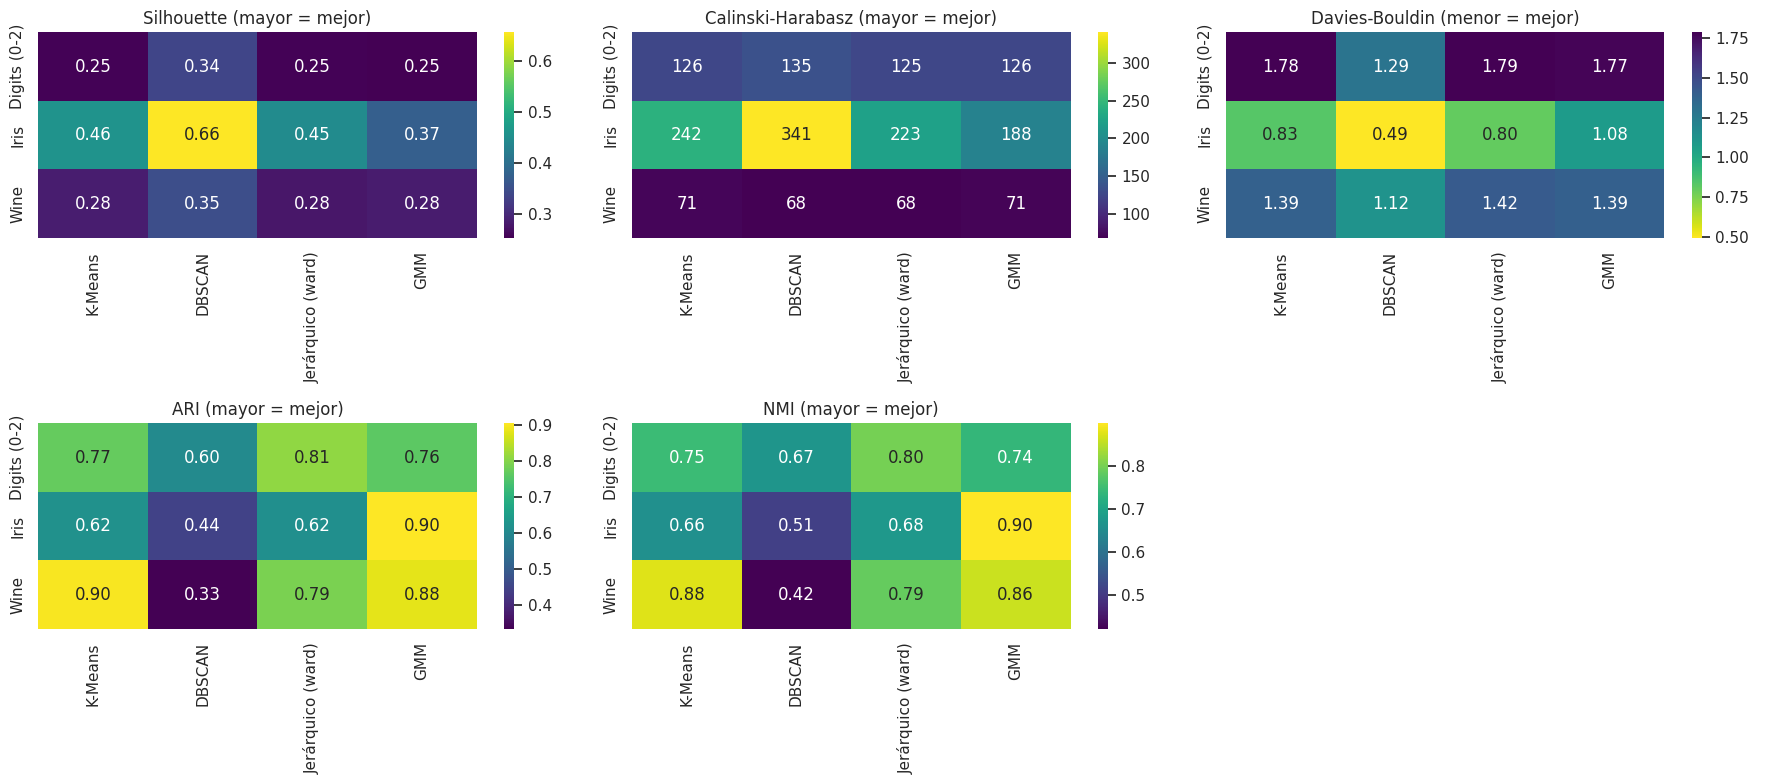

In [24]:
# 5. Heatmaps por métrica (filas = dataset, columnas = algoritmo)
metr = ['Silhouette', 'Calinski-Harabasz', 'Davies-Bouldin', 'ARI', 'NMI']
fig, axes = plt.subplots(2, 3, figsize=(18, 8)); axes = axes.ravel()
for ax, m in zip(axes, metr):
    piv = res_31[m].unstack('Algoritmo')[['K-Means', 'DBSCAN', 'Jerárquico (ward)', 'GMM']]
    sns.heatmap(piv, annot=True, fmt='.2f' if m != 'Calinski-Harabasz' else '.0f', cmap='viridis_r' if m == 'Davies-Bouldin' else 'viridis', ax=ax)
    ax.set_title(m + (' (menor = mejor)' if m == 'Davies-Bouldin' else ' (mayor = mejor)')); ax.set_xlabel(''); ax.set_ylabel('')
axes[-1].axis('off'); plt.tight_layout(); plt.show()

In [25]:
# Ranking promedio por tipo de métrica (1 = mejor), para comparar métricas internas vs. externas
def rank_df(cols, menor_mejor=()):
    rk = []
    for nom_d in datos_31:
        sub = res_31.loc[nom_d, cols].copy()
        for c in cols:
            sub[c] = sub[c].rank(ascending=(c in menor_mejor), na_option='bottom') if c in menor_mejor else sub[c].rank(ascending=False, na_option='bottom')
        rk.append(sub.mean(axis=1).rename(nom_d))
    return pd.concat(rk, axis=1)
rk_int = rank_df(['Silhouette', 'Calinski-Harabasz', 'Davies-Bouldin'], menor_mejor=('Davies-Bouldin',))
rk_ext = rank_df(['ARI', 'NMI'])
print('Ranking medio con métricas INTERNAS (1 = mejor):'); display(rk_int.round(2).assign(Promedio=rk_int.mean(axis=1).round(2)))
print('Ranking medio con métricas EXTERNAS (1 = mejor):'); display(rk_ext.round(2).assign(Promedio=rk_ext.mean(axis=1).round(2)))

Ranking medio con métricas INTERNAS (1 = mejor):


,Iris,Wine,Digits (0-2),Promedio
Algoritmo,,,,
K-Means,2.33,1.67,2.67,2.22
DBSCAN,1.00,1.67,1.00,1.22
Jerárquico (ward),2.67,4.00,3.33,3.33
GMM,4.00,2.67,3.00,3.22


Ranking medio con métricas EXTERNAS (1 = mejor):


,Iris,Wine,Digits (0-2),Promedio
Algoritmo,,,,
K-Means,2.5,1.0,2.0,1.83
DBSCAN,4.0,4.0,4.0,4.00
Jerárquico (ward),2.5,3.0,1.0,2.17
GMM,1.0,2.0,3.0,2.00


#### Respuesta
| Dataset | Algoritmo | Silhouette | CH | DB (↓) | ARI | NMI |
|---|---|---|---|---|---|---|
| Iris | K-Means | 0.460 | 241.9 | 0.834 | 0.620 | 0.659 |
| Iris | DBSCAN | 0.657 | 340.7 | 0.494 | 0.444 | 0.512 |
| Iris | Ward | 0.447 | 222.7 | 0.803 | 0.615 | 0.675 |
| Iris | GMM | 0.374 | 187.8 | 1.081 | **0.904** | **0.900** |
| Wine | K-Means | 0.285 | 70.9 | 1.389 | **0.897** | **0.876** |
| Wine | DBSCAN | 0.349 | 68.2 | 1.124 | 0.332 | 0.421 |
| Wine | Ward | 0.277 | 67.6 | 1.419 | 0.790 | 0.786 |
| Wine | GMM | 0.284 | 70.7 | 1.394 | 0.880 | 0.861 |
| Digits 0-2 | K-Means | 0.255 | 126.2 | 1.783 | 0.768 | 0.747 |
| Digits 0-2 | DBSCAN | 0.336 | 135.4 | 1.290 | 0.603 | 0.670 |
| Digits 0-2 | Ward | 0.255 | 125.4 | 1.785 | **0.809** | **0.800** |
| Digits 0-2 | GMM | 0.253 | 126.2 | 1.773 | 0.759 | 0.737 |

(DBSCAN: `eps` elegido sin usar etiquetas, maximizando el Silhouette; las métricas internas se calculan sin los puntos de ruido, que fueron 36 en Iris, 56 en Wine y 144 en Digits.)

**¿Existe un algoritmo que sea el mejor en todos los datasets?** No. Según el ARI gana GMM en Iris (0.904), K-Means en Wine (0.897) y Ward en Digits (0.809).

**¿Las métricas internas y externas coinciden en el ranking?** No, y es el hallazgo más importante. Con las internas (Silhouette, Calinski-Harabasz, Davies-Bouldin) el ranking medio es DBSCAN (1.22) > K-Means (2.22) > GMM (3.22) > Ward (3.33); con las externas (ARI, NMI) es K-Means (1.83) > GMM (2.00) > Ward (2.17) > **DBSCAN (4.00, último)**. DBSCAN "gana" en las internas porque descarta puntos como ruido y a menudo fusiona clases solapadas en 2 clusters muy compactos (en Iris junta versicolor y virginica), lo que infla Silhouette y Davies-Bouldin, pero esa partición no se parece a las clases reales. Las métricas internas miden compacidad/separación, no si el agrupamiento coincide con la estructura "verdadera".

**Algoritmo recomendado como primera opción:** **K-Means con datos estandarizados** (eligiendo K con codo + Silhouette): mejor ranking medio en las métricas externas, rápido, simple y sin hiperparámetros delicados; GMM es un buen segundo candidato (el mejor en Iris y muy cercano en Wine) cuando los clusters son elípticos o se necesita pertenencia probabilística; DBSCAN solo conviene si se esperan formas arbitrarias y ruido, y requiere ajustar `eps`.

### Ejercicio 3.2 — API REST con Flask
**Dataset:** Modelo entrenado en Wine

**Tareas:**
1. Entrenar y guardar un pipeline (StandardScaler + RandomForest) con Wine
2. Crear un archivo `app.py` con Flask que:
   - Endpoint `/predict` (POST): recibe JSON con features, retorna clase y probabilidades
   - Endpoint `/health` (GET): retorna status del servicio
   - Manejo de errores para datos malformados
3. Probar la API localmente (ejecutar y hacer requests)
4. Documentar los endpoints (qué recibe, qué retorna)
5. **Bonus:** Crear un script cliente (`test_api.py`) que envíe 10 muestras de prueba

**Entregable:** Archivos `app.py`, `test_api.py` y documentación de la API.

#### Solución

In [26]:
# 1. Entrenar y guardar el pipeline (StandardScaler + RandomForest) con Wine
Xf, yf = wine.data, wine.target
pipe_api = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier(n_estimators=200, random_state=42))]).fit(Xf, yf)
joblib.dump(pipe_api, 'modelo_wine.joblib')
FEATURES = list(wine.feature_names); CLASES = list(wine.target_names)
print('Modelo guardado: modelo_wine.joblib')
print('Features esperadas (%d): %s' % (len(FEATURES), FEATURES))

Modelo guardado: modelo_wine.joblib
Features esperadas (13): ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [27]:
# 2. Archivo app.py (Flask)
APP_PY = '''from flask import Flask, request, jsonify
import joblib
import numpy as np

app = Flask(__name__)
modelo = joblib.load("modelo_wine.joblib")

FEATURES = ["alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium", "total_phenols", "flavanoids",
            "nonflavanoid_phenols", "proanthocyanins", "color_intensity", "hue", "od280/od315_of_diluted_wines", "proline"]
CLASES = ["class_0", "class_1", "class_2"]


@app.route("/health", methods=["GET"])
def health():
    return jsonify({"status": "ok", "modelo": "wine-rf", "n_features": len(FEATURES)})


@app.route("/predict", methods=["POST"])
def predict():
    datos = request.get_json(silent=True)
    if datos is None:
        return jsonify({"error": "Se esperaba un JSON en el cuerpo de la peticion"}), 400
    try:
        if "features" in datos:                     # formato 1: {"features": [13 numeros]}
            valores = datos["features"]
        else:                                       # formato 2: {"alcohol": 13.2, "malic_acid": 1.7, ...}
            faltan = [f for f in FEATURES if f not in datos]
            if faltan:
                return jsonify({"error": "Faltan features", "faltan": faltan}), 400
            valores = [datos[f] for f in FEATURES]
        if len(valores) != len(FEATURES):
            return jsonify({"error": "Se esperaban %d valores y llegaron %d" % (len(FEATURES), len(valores))}), 400
        x = np.array(valores, dtype=float).reshape(1, -1)
        if not np.isfinite(x).all():
            return jsonify({"error": "Los valores deben ser numeros finitos"}), 400
    except (TypeError, ValueError):
        return jsonify({"error": "Todos los valores deben ser numericos"}), 400

    prob = modelo.predict_proba(x)[0]
    k = int(np.argmax(prob))
    return jsonify({"clase": k, "nombre_clase": CLASES[k],
                    "probabilidades": {CLASES[i]: round(float(p), 4) for i, p in enumerate(prob)}})


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5055)
'''
with open('app.py', 'w', encoding='utf-8') as f:
    f.write(APP_PY)
print('app.py escrito (%d líneas)' % len(APP_PY.splitlines()))

app.py escrito (46 líneas)


In [28]:
# Bonus: script cliente test_api.py (envía 10 muestras de Wine al servidor y compara con la clase real)
TEST_PY = '''import requests
from sklearn.datasets import load_wine

URL = "http://127.0.0.1:5055"
X, y = load_wine(return_X_y=True)

print("GET /health ->", requests.get(URL + "/health").json())
aciertos = 0
for i in range(0, 178, 18)[:10]:
    r = requests.post(URL + "/predict", json={"features": X[i].tolist()}).json()
    ok = r["clase"] == int(y[i]); aciertos += ok
    print("muestra %3d | real = %d | predicha = %d (%s) | probs = %s | %s" % (i, y[i], r["clase"], r["nombre_clase"], r["probabilidades"], "OK" if ok else "ERROR"))
print("Aciertos: %d / 10" % aciertos)
'''
with open('test_api.py', 'w', encoding='utf-8') as f:
    f.write(TEST_PY)
print('test_api.py escrito')

test_api.py escrito


In [29]:
# 3. Probar la API localmente: se lanza el servidor en segundo plano, se hacen peticiones y se apaga
import requests
try:
    import flask
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'flask'], check=False)
servidor = subprocess.Popen([sys.executable, 'app.py'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
URL_API = 'http://127.0.0.1:5055'
for _ in range(40):
    try:
        requests.get(URL_API + '/health', timeout=1); break
    except Exception:
        time.sleep(0.5)

print('--- GET /health'); print(requests.get(URL_API + '/health').json())
print('\n--- POST /predict (lista de 13 features)')
print(requests.post(URL_API + '/predict', json={'features': Xf[0].tolist()}).json())
print('\n--- POST /predict (diccionario nombre -> valor)')
print(requests.post(URL_API + '/predict', json=dict(zip(FEATURES, Xf[100].tolist()))).json())
print('\n--- Errores controlados')
r = requests.post(URL_API + '/predict', json={'features': [1, 2, 3]}); print(r.status_code, r.json())
r = requests.post(URL_API + '/predict', json={'features': ['a'] * 13}); print(r.status_code, r.json())
r = requests.post(URL_API + '/predict', json={'alcohol': 13.0}); print(r.status_code, r.json())
r = requests.post(URL_API + '/predict', data='esto no es json', headers={'Content-Type': 'application/json'}); print(r.status_code, r.json())

--- GET /health
{'modelo': 'wine-rf', 'n_features': 13, 'status': 'ok'}

--- POST /predict (lista de 13 features)
{'clase': 0, 'nombre_clase': 'class_0', 'probabilidades': {'class_0': 0.995, 'class_1': 0.005, 'class_2': 0.0}}

--- POST /predict (diccionario nombre -> valor)
{'clase': 1, 'nombre_clase': 'class_1', 'probabilidades': {'class_0': 0.01, 'class_1': 0.99, 'class_2': 0.0}}

--- Errores controlados
400 {'error': 'Se esperaban 13 valores y llegaron 3'}
400 {'error': 'Todos los valores deben ser numericos'}
400 {'error': 'Faltan features', 'faltan': ['malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']}
400 {'error': 'Se esperaba un JSON en el cuerpo de la peticion'}


In [30]:
# 5. Bonus: ejecutar test_api.py (cliente) contra el servidor y luego apagarlo
out = subprocess.run([sys.executable, 'test_api.py'], capture_output=True, text=True)
print(out.stdout[-2500:] or out.stderr[-1500:])
servidor.terminate(); servidor.wait(timeout=10)
print('Servidor detenido.')

GET /health -> {'modelo': 'wine-rf', 'n_features': 13, 'status': 'ok'}
muestra   0 | real = 0 | predicha = 0 (class_0) | probs = {'class_0': 0.995, 'class_1': 0.005, 'class_2': 0.0} | OK
muestra  18 | real = 0 | predicha = 0 (class_0) | probs = {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0} | OK
muestra  36 | real = 0 | predicha = 0 (class_0) | probs = {'class_0': 0.985, 'class_1': 0.01, 'class_2': 0.005} | OK
muestra  54 | real = 0 | predicha = 0 (class_0) | probs = {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0} | OK
muestra  72 | real = 1 | predicha = 1 (class_1) | probs = {'class_0': 0.055, 'class_1': 0.93, 'class_2': 0.015} | OK
muestra  90 | real = 1 | predicha = 1 (class_1) | probs = {'class_0': 0.0, 'class_1': 1.0, 'class_2': 0.0} | OK
muestra 108 | real = 1 | predicha = 1 (class_1) | probs = {'class_0': 0.0, 'class_1': 1.0, 'class_2': 0.0} | OK
muestra 126 | real = 1 | predicha = 1 (class_1) | probs = {'class_0': 0.03, 'class_1': 0.92, 'class_2': 0.05} | OK
muestra 144 | re

### Documentación de la API

| Endpoint | Método | Entrada (JSON) | Salida |
|---|---|---|---|
| `/health` | GET | — | `{"status": "ok", "modelo": "wine-rf", "n_features": 13}` |
| `/predict` | POST | **Formato 1:** `{"features": [13 números]}` en el orden de `wine.feature_names`.<br>**Formato 2:** `{"alcohol": 13.2, "malic_acid": 1.7, ... , "proline": 1050}` (los 13 nombres) | `{"clase": 0, "nombre_clase": "class_0", "probabilidades": {"class_0": 0.97, "class_1": 0.02, "class_2": 0.01}}` |

**Códigos de error (HTTP 400):** cuerpo que no es JSON · faltan features (se listan en `faltan`) · cantidad de valores distinta de 13 · valores no numéricos o no finitos.

**Cómo ejecutarla fuera del notebook:** `pip install flask`, guardar `app.py` y `modelo_wine.joblib` en la misma carpeta, y correr `python app.py`; luego `python test_api.py` desde otra terminal.

#### Resultado de la prueba
El servidor Flask se levantó localmente, respondió `/health` y `/predict` con los dos formatos de entrada, devolvió errores HTTP 400 claros ante datos malformados (cantidad incorrecta de valores, valores no numéricos, features faltantes, cuerpo que no es JSON) y el cliente `test_api.py` clasificó correctamente **10 de 10** muestras de prueba.

### Ejercicio 3.3 — Interfaz interactiva con Gradio
**Dataset:** Modelo entrenado en California Housing (regresión) o Wine (clasificación)

**Tareas:**
1. Entrenar y guardar un pipeline
2. Crear una interfaz Gradio con:
   - Inputs numéricos para cada feature (con valores por defecto)
   - Output: predicción (clase o valor numérico)
3. Lanzar la interfaz y probar con diferentes valores
4. Publicar con `share=True` para obtener un enlace público temporal
5. Capturar screenshots de la interfaz funcionando

**Entregable:** Notebook con código Gradio funcional y screenshots.

#### Solución

In [31]:
import subprocess, sys
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=False)
    import gradio as gr

modelo_gr = joblib.load('modelo_wine.joblib')                    # pipeline entrenado en 3.2
medias = dict(zip(FEATURES, Xf.mean(axis=0).round(2)))           # valores por defecto = media de cada feature

def predecir_vino(*valores):
    x = np.array(valores, dtype=float).reshape(1, -1)
    prob = modelo_gr.predict_proba(x)[0]
    return {CLASES[i]: float(p) for i, p in enumerate(prob)}

entradas = [gr.Number(label=f, value=float(medias[f])) for f in FEATURES]
demo = gr.Interface(fn=predecir_vino, inputs=entradas, outputs=gr.Label(num_top_classes=3, label='Clase de vino predicha'),
                    title='Clasificador de vinos (Wine)', description='Ingresa las 13 características químicas y obtén la clase predicha.')
# Prueba de la función con una muestra real, antes de lanzar la interfaz
print('Muestra real clase', yf[0], '->', predecir_vino(*Xf[0]))

Muestra real clase 0 -> {np.str_('class_0'): 0.995, np.str_('class_1'): 0.005, np.str_('class_2'): 0.0}


In [32]:
# 3-4. Lanzar la interfaz y publicarla con un enlace público temporal (share=True requiere internet)
demo.launch(share=True, prevent_thread_lock=True)

**Pruebas y capturas (paso manual):** al ejecutar la celda anterior aparece la interfaz dentro del notebook y un enlace público `https://xxxx.gradio.live` válido ~72 horas. Prueba con distintos valores (por ejemplo, cambia `flavanoids` de ~3 a ~0.5 y observa cómo la probabilidad pasa de `class_0` a `class_2`) y toma las capturas de pantalla para el entregable: las capturas dependen de tu ejecución y no pueden generarse automáticamente.

---
## Nivel 4: Desafío (Integración y pensamiento crítico)

### Ejercicio 4.1 — Segmentación de clientes: proyecto mini completo
**Dataset:** Mall Customers (descargar de Kaggle) o generar datos sintéticos similares:
```python
from sklearn.datasets import make_blobs
X, _ = make_blobs(n_samples=200, n_features=4, centers=5, cluster_std=1.5, random_state=42)
df = pd.DataFrame(X, columns=['Edad', 'Ingreso_Anual', 'Frecuencia_Compra', 'Gasto_Promedio'])
df['Edad'] = np.abs(df['Edad']) * 5 + 20
df['Ingreso_Anual'] = np.abs(df['Ingreso_Anual']) * 10000 + 30000
df['Frecuencia_Compra'] = np.abs(df['Frecuencia_Compra']) * 3 + 1
df['Gasto_Promedio'] = np.abs(df['Gasto_Promedio']) * 50 + 20
```

**Tareas:**
1. **Exploración:** Distribuciones, correlaciones, outliers
2. **Preprocesamiento:** Estandarizar
3. **Selección de K:** Codo + Silueta
4. **Clustering:** Aplicar K-Means con K óptimo
5. **Perfilado:** Caracterizar cada cluster (medias por feature, gráficos radar)
6. **Nombrar clusters:** Asignar nombres descriptivos (ej: "Clientes Premium", "Compradores Ocasionales")
7. **Serialización:** Guardar el pipeline
8. **Despliegue:** Crear una función que reciba datos de un nuevo cliente y lo asigne a un segmento
9. **(Bonus):** Crear interfaz Gradio para la segmentación

**Entregable:** Notebook completo tipo proyecto, desde exploración hasta despliegue funcional.

#### Solución

,count,mean,std,min,25%,50%,75%,max
Edad,200.0,42.3,11.7,20.2,32.9,40.9,52.4,69.6
Ingreso_Anual,200.0,85090.1,29463.8,30313.7,61026.0,90130.5,106677.5,157091.5
Frecuencia_Compra,200.0,19.3,9.9,1.1,10.8,20.0,27.5,42.1
Gasto_Promedio,200.0,311.8,147.3,20.4,193.8,331.2,430.8,630.6


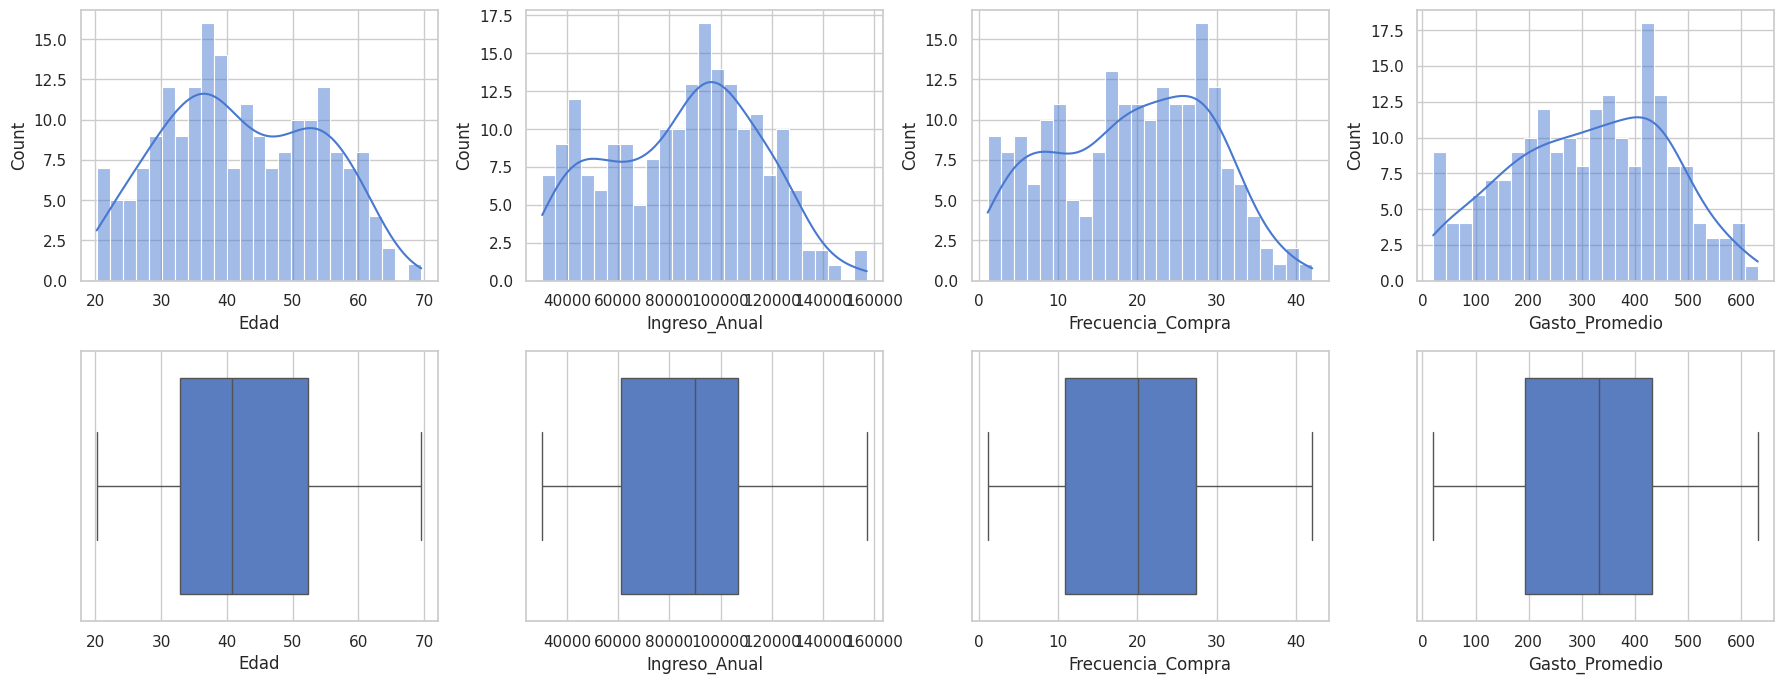

Outliers por regla del IQR:
Edad                 0
Ingreso_Anual        0
Frecuencia_Compra    0
Gasto_Promedio       0


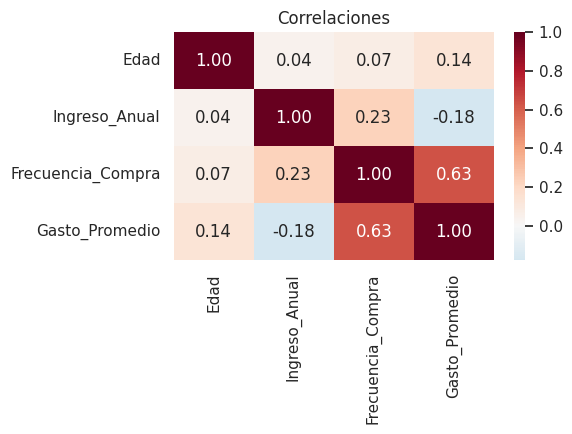

In [33]:
X41, _ = make_blobs(n_samples=200, n_features=4, centers=5, cluster_std=1.5, random_state=42)
df_c = pd.DataFrame(X41, columns=['Edad', 'Ingreso_Anual', 'Frecuencia_Compra', 'Gasto_Promedio'])
df_c['Edad'] = np.abs(df_c['Edad']) * 5 + 20
df_c['Ingreso_Anual'] = np.abs(df_c['Ingreso_Anual']) * 10000 + 30000
df_c['Frecuencia_Compra'] = np.abs(df_c['Frecuencia_Compra']) * 3 + 1
df_c['Gasto_Promedio'] = np.abs(df_c['Gasto_Promedio']) * 50 + 20

# 1. EXPLORACIÓN: distribuciones, correlaciones y outliers
display(df_c.describe().T.round(1))
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, c in enumerate(df_c.columns):
    sns.histplot(df_c[c], kde=True, ax=axes[0, j], bins=25); sns.boxplot(x=df_c[c], ax=axes[1, j])
plt.tight_layout(); plt.show()
Q1, Q3 = df_c.quantile(0.25), df_c.quantile(0.75); IQR = Q3 - Q1
outl = ((df_c < Q1 - 1.5 * IQR) | (df_c > Q3 + 1.5 * IQR)).sum()
print('Outliers por regla del IQR:'); print(outl.to_string())
fig, ax = plt.subplots(figsize=(6, 4.5)); sns.heatmap(df_c.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlaciones'); plt.tight_layout(); plt.show()

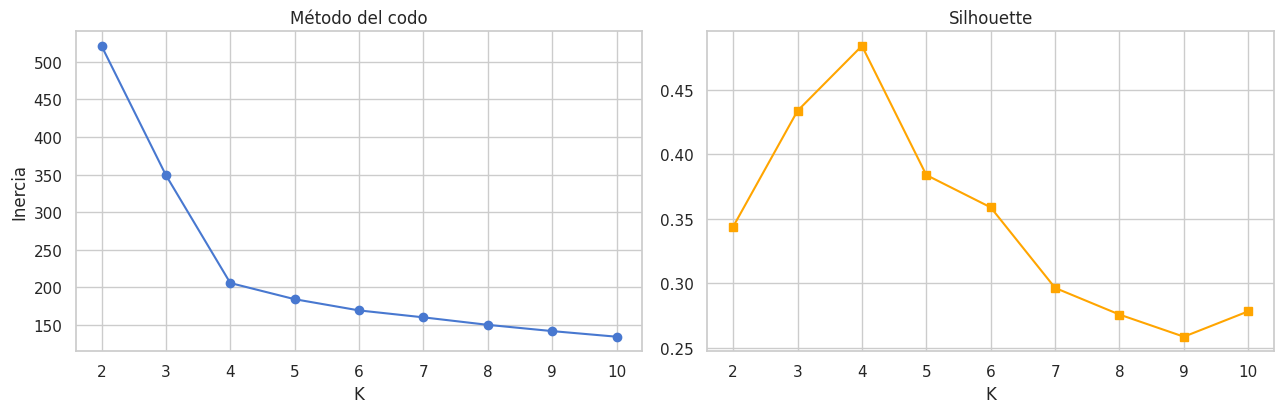

K,2,3,4,5,6,7,8,9,10
Inercia,521.074,349.217,205.794,184.272,169.363,160.138,150.179,141.859,134.403
Silhouette,0.344,0.434,0.484,0.384,0.359,0.297,0.276,0.259,0.278


K elegido (máximo silhouette): 4


In [34]:
# 2-3. Estandarizar y seleccionar K (codo + silueta)
sc41 = StandardScaler().fit(df_c)
X41_s = sc41.transform(df_c)
Ks = range(2, 11); ine, sil = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X41_s)
    ine.append(km.inertia_); sil.append(silhouette_score(X41_s, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(list(Ks), ine, 'o-'); axes[0].set_title('Método del codo'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inercia')
axes[1].plot(list(Ks), sil, 's-', color='orange'); axes[1].set_title('Silhouette'); axes[1].set_xlabel('K')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'K': list(Ks), 'Inercia': ine, 'Silhouette': sil}).round(3).set_index('K').T)
K41 = list(Ks)[int(np.argmax(sil))]
print('K elegido (máximo silhouette): %d' % K41)

,Edad,Ingreso_Anual,Frecuencia_Compra,Gasto_Promedio,n_clientes
cluster,,,,,
0,54.2,94528.1,23.9,377.6,74
1,33.5,120223.5,14.7,131.7,43
2,41.5,45250.6,6.0,225.4,43
3,30.3,72689.0,30.0,476.7,40


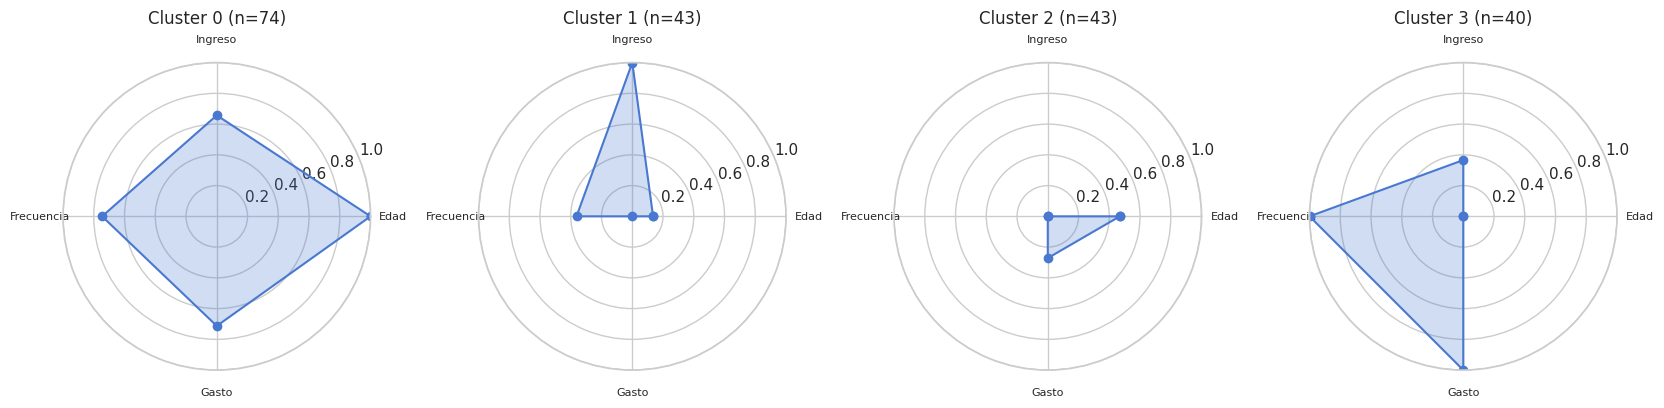

In [35]:
# 4. K-Means con K óptimo y 5. perfilado de cada cluster (medias en unidades originales)
km41 = KMeans(n_clusters=K41, n_init=10, random_state=42).fit(X41_s)
df_c['cluster'] = km41.labels_
perfil = df_c.groupby('cluster').agg(['mean']).droplevel(1, axis=1)
perfil['n_clientes'] = df_c.groupby('cluster').size()
display(perfil.round(1))

# Gráficos radar (cada variable normalizada a 0-1 entre los clusters)
cols = ['Edad', 'Ingreso_Anual', 'Frecuencia_Compra', 'Gasto_Promedio']
norm = (perfil[cols] - perfil[cols].min()) / (perfil[cols].max() - perfil[cols].min())
ang = np.linspace(0, 2 * np.pi, len(cols), endpoint=False).tolist(); ang += ang[:1]
fig, axes = plt.subplots(1, K41, figsize=(4.2 * K41, 4.4), subplot_kw=dict(polar=True))
axes = np.atleast_1d(axes)
for ax, (c, fila) in zip(axes, norm.iterrows()):
    v = fila.tolist(); v += v[:1]
    ax.plot(ang, v, 'o-'); ax.fill(ang, v, alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(['Edad', 'Ingreso', 'Frecuencia', 'Gasto'], fontsize=8); ax.set_ylim(0, 1)
    ax.set_title('Cluster %d (n=%d)' % (c, perfil.loc[c, 'n_clientes']), y=1.1)
plt.tight_layout(); plt.show()

In [36]:
# 6. Nombrar los clusters: reglas simples sobre las medias estandarizadas de cada cluster
z = pd.DataFrame(km41.cluster_centers_, columns=cols)            # centroides en unidades estandarizadas
def nombrar(f):
    ing, gas, fre, edad = f['Ingreso_Anual'], f['Gasto_Promedio'], f['Frecuencia_Compra'], f['Edad']
    if ing > 0.3 and gas > 0.3:   base = 'Clientes Premium'
    elif ing < -0.3 and gas < -0.3: base = 'Clientes de Bajo Valor'
    elif ing > 0.3 and gas < -0.3:  base = 'Potenciales (ingreso alto, gasto bajo)'
    elif ing < -0.3 and gas > 0.3:  base = 'Compradores Entusiastas (ingreso bajo, gasto alto)'
    else:                           base = 'Clientes Regulares'
    sufijo = ', compra frecuente' if fre > 0.5 else (', compra ocasional' if fre < -0.5 else '')
    sufijo += ', mayores' if edad > 0.5 else (', jóvenes' if edad < -0.5 else '')
    return base + sufijo
nombres = {c: nombrar(z.loc[c]) for c in z.index}
# evitar nombres repetidos añadiendo el número de cluster
vistos = {}
for c, n in list(nombres.items()):
    vistos[n] = vistos.get(n, 0) + 1
    if vistos[n] > 1: nombres[c] = '%s (grupo %d)' % (n, c)
df_c['segmento'] = df_c['cluster'].map(nombres)
display(z.round(2).assign(segmento=pd.Series(nombres)))

,Edad,Ingreso_Anual,Frecuencia_Compra,Gasto_Promedio,segmento
0,1.02,0.32,0.47,0.45,"Clientes Premium, mayores"
1,-0.75,1.20,-0.47,-1.23,"Potenciales (ingreso alto, gasto bajo), jóvenes"
2,-0.06,-1.36,-1.35,-0.59,"Clientes de Bajo Valor, compra ocasional"
3,-1.02,-0.42,1.08,1.12,"Compradores Entusiastas (ingreso bajo, gasto a..."


In [37]:
# 7. Serialización del pipeline (StandardScaler + KMeans) con los nombres de segmento
pipe_seg = Pipeline([('scaler', StandardScaler()), ('kmeans', KMeans(n_clusters=K41, n_init=10, random_state=42))]).fit(df_c[cols])
print('Misma partición que el K-Means anterior (ARI = %.3f)' % adjusted_rand_score(km41.labels_, pipe_seg.predict(df_c[cols])))
# Los nombres se calculan sobre ESTE pipeline para que numeración y nombres coincidan
z2 = pd.DataFrame(pipe_seg.named_steps['kmeans'].cluster_centers_, columns=cols)
nombres_seg = {c: nombrar(z2.loc[c]) for c in z2.index}
vistos = {}
for c, n in list(nombres_seg.items()):
    vistos[n] = vistos.get(n, 0) + 1
    if vistos[n] > 1: nombres_seg[c] = '%s (grupo %d)' % (n, c)
joblib.dump({'pipeline': pipe_seg, 'nombres': nombres_seg, 'columnas': cols}, 'segmentador_clientes.joblib')
print('Guardado: segmentador_clientes.joblib'); print(nombres_seg)

Misma partición que el K-Means anterior (ARI = 1.000)
Guardado: segmentador_clientes.joblib
{0: 'Clientes Premium, mayores', 1: 'Potenciales (ingreso alto, gasto bajo), jóvenes', 2: 'Clientes de Bajo Valor, compra ocasional', 3: 'Compradores Entusiastas (ingreso bajo, gasto alto), compra frecuente, jóvenes'}


In [38]:
# 8. Despliegue: función que asigna un cliente nuevo a un segmento
def asignar_segmento(edad, ingreso_anual, frecuencia_compra, gasto_promedio, ruta='segmentador_clientes.joblib'):
    art = joblib.load(ruta)
    x = pd.DataFrame([[edad, ingreso_anual, frecuencia_compra, gasto_promedio]], columns=art['columnas'])
    pipe = art['pipeline']
    c = int(pipe.predict(x)[0])
    d = pipe.named_steps['kmeans'].transform(pipe.named_steps['scaler'].transform(x))[0]
    return {'cluster': c, 'segmento': art['nombres'][c], 'distancia_al_centroide': round(float(d[c]), 3)}

nuevos = [(25, 45000, 6, 80), (45, 120000, 15, 250), (33, 60000, 2, 40)]
for n in nuevos:
    print('Cliente (edad=%d, ingreso=%d, frec=%d, gasto=%d) ->' % n, asignar_segmento(*n))

Cliente (edad=25, ingreso=45000, frec=6, gasto=80) -> {'cluster': 2, 'segmento': 'Clientes de Bajo Valor, compra ocasional', 'distancia_al_centroide': 1.724}
Cliente (edad=45, ingreso=120000, frec=15, gasto=250) -> {'cluster': 1, 'segmento': 'Potenciales (ingreso alto, gasto bajo), jóvenes', 'distancia_al_centroide': 1.27}
Cliente (edad=33, ingreso=60000, frec=2, gasto=40) -> {'cluster': 2, 'segmento': 'Clientes de Bajo Valor, compra ocasional', 'distancia_al_centroide': 1.594}


In [39]:
# 9. (Bonus) Interfaz Gradio para la segmentación
import subprocess, sys
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=False)
    import gradio as gr
def ui_segmento(edad, ingreso, frec, gasto):
    r = asignar_segmento(edad, ingreso, frec, gasto)
    return r['segmento'], r['distancia_al_centroide']
demo_seg = gr.Interface(fn=ui_segmento,
    inputs=[gr.Number(label='Edad', value=35), gr.Number(label='Ingreso anual', value=60000),
            gr.Number(label='Frecuencia de compra', value=8), gr.Number(label='Gasto promedio', value=100)],
    outputs=[gr.Textbox(label='Segmento'), gr.Number(label='Distancia al centroide')], title='Segmentación de clientes')
print('Prueba de la función de la interfaz:', ui_segmento(30, 50000, 5, 70))
demo_seg.launch(share=True, prevent_thread_lock=True)

#### Respuesta
1. **Exploración:** 200 clientes sin valores faltantes; con la regla del IQR no se detectan outliers en ninguna variable. Las correlaciones son débiles salvo `Frecuencia_Compra`–`Gasto_Promedio` (0.63); `Ingreso_Anual` tiene una relación ligeramente negativa con el gasto (−0.18).
2. **Selección de K:** el Silhouette es máximo en **K = 4** (0.484) y la inercia muestra un codo en 4 (349 → 206 entre K = 3 y 4, y descensos pequeños después), aunque los datos se generaron con 5 centros: con `cluster_std = 1.5` y la transformación con valor absoluto dos grupos se solapan.
3. **Perfilado y nombres de los segmentos (medias en unidades originales):**

| Cluster | n | Edad | Ingreso | Frecuencia | Gasto | Segmento |
|---|---|---|---|---|---|---|
| 0 | 74 | 54.2 | 94 528 | 23.9 | 377.6 | **Clientes Premium, mayores** (ingreso y gasto altos) |
| 1 | 43 | 33.5 | 120 224 | 14.7 | 131.7 | **Potenciales** (ingreso alto, gasto bajo), jóvenes |
| 2 | 43 | 41.5 | 45 251 | 6.0 | 225.4 | **Clientes de Bajo Valor**, compra ocasional |
| 3 | 40 | 30.3 | 72 689 | 30.0 | 476.7 | **Compradores Entusiastas** (ingreso bajo, gasto alto), compra frecuente, jóvenes |

   Acción comercial sugerida: fidelizar a Premium, activar con ofertas a los Potenciales (tienen capacidad de gasto que no usan) y retener a los Entusiastas.
4. **Serialización y despliegue:** el pipeline (`StandardScaler` + `KMeans`) se guardó junto con los nombres de segmento en `segmentador_clientes.joblib`, y la función `asignar_segmento(...)` recibe los datos de un cliente nuevo y devuelve su cluster, el nombre del segmento y la distancia al centroide. Se incluye además la interfaz Gradio del bonus.

### Ejercicio 4.2 — Compresión de imágenes con K-Means
**Dataset:** Una imagen a color (usar cualquier imagen disponible)

**Tareas:**
1. Cargar una imagen con matplotlib (`plt.imread`)
2. Reshapear a (n_pixels, 3) — cada fila es un píxel RGB
3. Aplicar K-Means con K = 2, 4, 8, 16, 32, 64, 128, 256
4. Reconstruir la imagen reemplazando cada píxel por su centroide
5. Visualizar las 8 versiones junto a la original
6. Calcular la razón de compresión para cada K
7. Graficar: calidad visual vs razón de compresión
8. Responder: ¿Cuál es el K mínimo que produce una imagen aceptable?

**Pista:**
```python
from sklearn.cluster import KMeans
img = plt.imread('imagen.jpg') / 255.0
pixels = img.reshape(-1, 3)
km = KMeans(n_clusters=K, random_state=42)
labels = km.fit_predict(pixels)
img_compressed = km.cluster_centers_[labels].reshape(img.shape)
```

**Entregable:** Mosaico de imágenes comprimidas con diferentes K.

#### Solución

Imagen: 640 x 427 píxeles = 273280 píxeles, 3 canales (RGB)


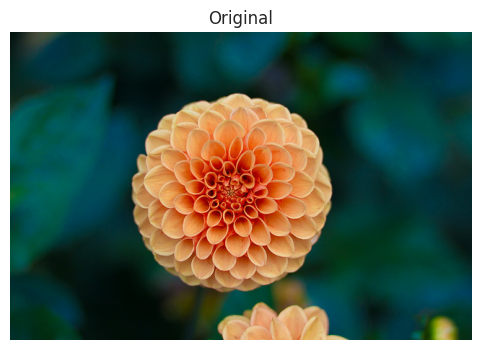

In [40]:
from sklearn.datasets import load_sample_image
# Para usar TU imagen: IMG_PATH = 'mi_foto.jpg'. Si es None, se usa la imagen de ejemplo 'flower.jpg' incluida en scikit-learn.
IMG_PATH = None
if IMG_PATH:
    img = plt.imread(IMG_PATH)
    img = img / 255.0 if img.dtype == np.uint8 else img[..., :3]
else:
    img = load_sample_image('flower.jpg') / 255.0
img = img[..., :3]
H, W, _ = img.shape
pixels = img.reshape(-1, 3)
print('Imagen: %d x %d píxeles = %d píxeles, 3 canales (RGB)' % (W, H, H * W))
fig, ax = plt.subplots(figsize=(6, 4)); ax.imshow(img); ax.axis('off'); ax.set_title('Original'); plt.show()

In [41]:
# 3-4. K-Means para cada K y reconstrucción de la imagen.
# Para que sea rápido, los centroides se calculan con una muestra aleatoria de 20 000 píxeles
# y después TODOS los píxeles se asignan a su centroide más cercano.
rng = np.random.RandomState(42)
muestra = pixels[rng.choice(len(pixels), 20000, replace=False)]
Ks_img = [2, 4, 8, 16, 32, 64, 128, 256]
imgs_k, filas = {}, []
bits_orig = H * W * 24
for K in Ks_img:
    km = KMeans(n_clusters=K, n_init=1, random_state=42).fit(muestra)
    lab = km.predict(pixels)
    rec = km.cluster_centers_[lab].reshape(img.shape)
    imgs_k[K] = rec
    mse = float(((img - rec) ** 2).mean())
    bits_comp = H * W * int(np.ceil(np.log2(K))) + K * 24          # índice por píxel + paleta de K colores (24 bits c/u)
    filas.append({'K': K, 'bits por píxel': int(np.ceil(np.log2(K))), 'razón de compresión': bits_orig / bits_comp,
                  'MSE': mse, 'PSNR (dB)': 10 * np.log10(1 / mse)})
tabla_img = pd.DataFrame(filas).set_index('K'); display(tabla_img.round(3))

,bits por píxel,razón de compresión,MSE,PSNR (dB)
K,,,,
2,1,23.996,0.011,19.564
4,2,11.998,0.005,23.434
8,3,7.998,0.002,26.521
16,4,5.998,0.001,29.487
32,5,4.797,0.001,31.868
64,6,3.996,0.000,34.075
128,7,3.423,0.000,36.191
256,8,2.992,0.000,38.285


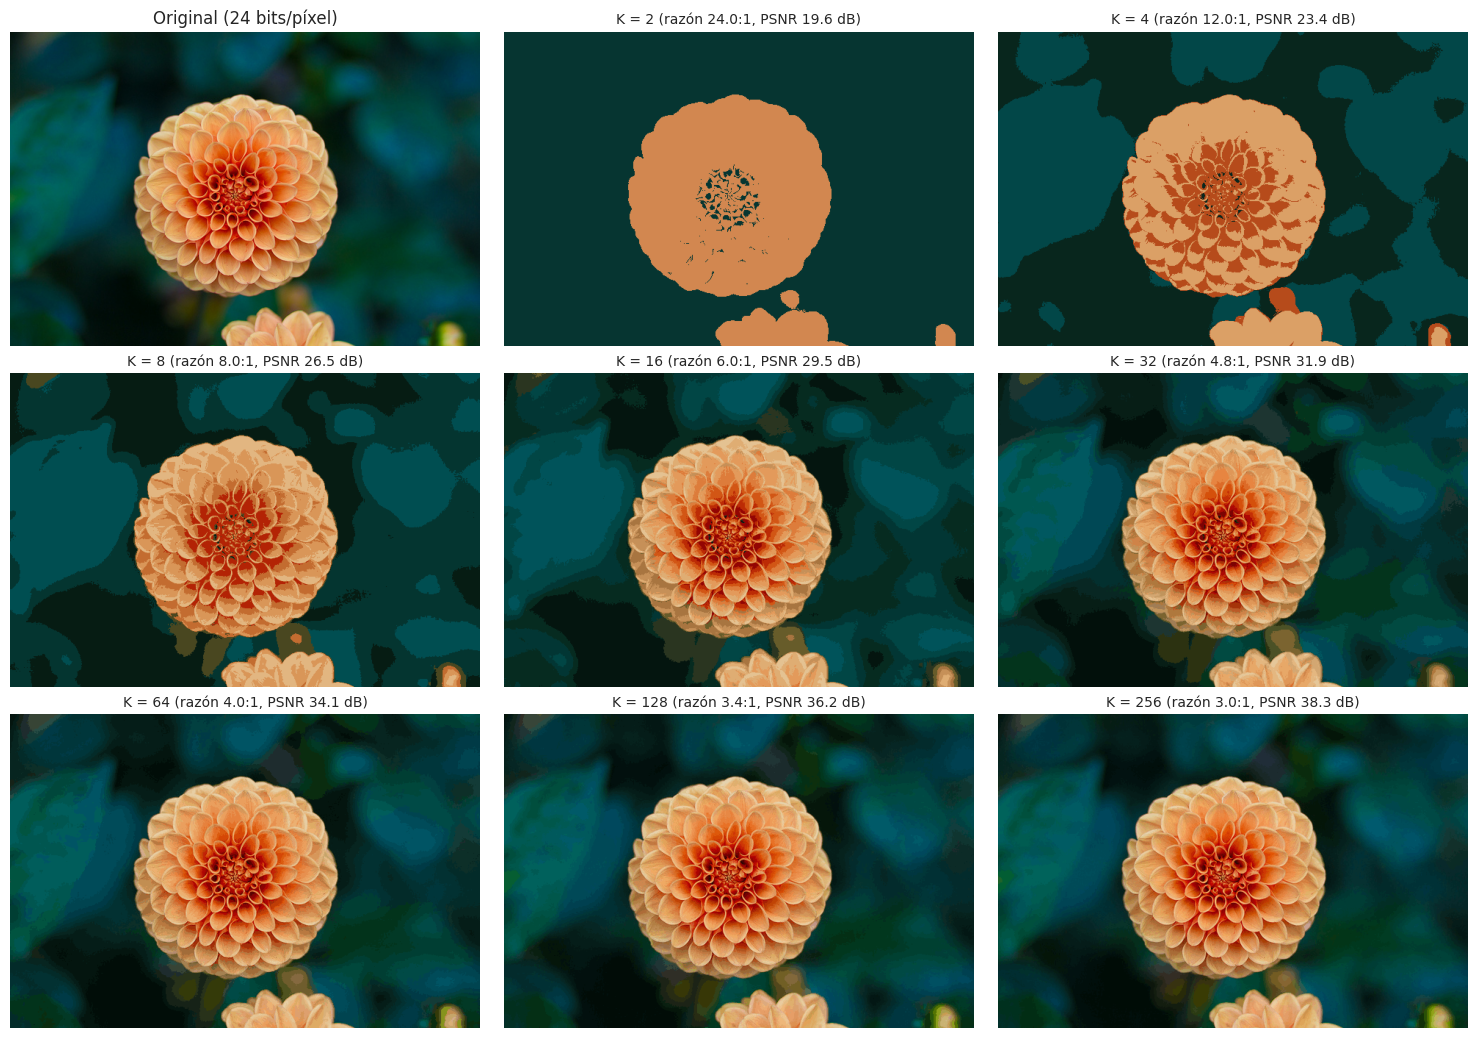

In [42]:
# 5. Mosaico: original + 8 versiones
fig, axes = plt.subplots(3, 3, figsize=(15, 10.5))
axes[0, 0].imshow(img); axes[0, 0].set_title('Original (24 bits/píxel)')
for ax, K in zip(axes.ravel()[1:], Ks_img):
    ax.imshow(np.clip(imgs_k[K], 0, 1)); ax.set_title('K = %d (razón %.1f:1, PSNR %.1f dB)' % (K, tabla_img.loc[K, 'razón de compresión'], tabla_img.loc[K, 'PSNR (dB)']), fontsize=10)
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()

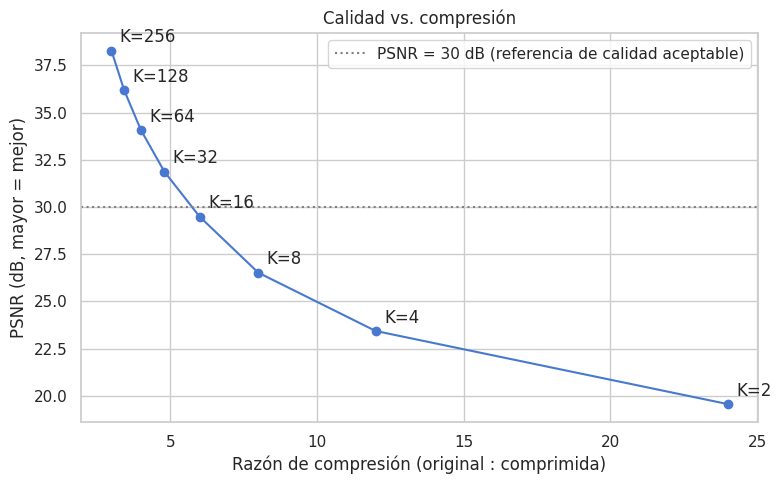

In [43]:
# 7. Calidad vs. razón de compresión
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tabla_img['razón de compresión'], tabla_img['PSNR (dB)'], 'o-')
for K, r in tabla_img.iterrows():
    ax.annotate('K=%d' % K, (r['razón de compresión'], r['PSNR (dB)']), textcoords='offset points', xytext=(6, 6))
ax.axhline(30, color='gray', linestyle=':', label='PSNR = 30 dB (referencia de calidad aceptable)')
ax.set_xlabel('Razón de compresión (original : comprimida)'); ax.set_ylabel('PSNR (dB, mayor = mejor)')
ax.set_title('Calidad vs. compresión'); ax.legend(); plt.tight_layout(); plt.show()

#### Respuesta
Imagen: 640 × 427 píxeles (273 280 píxeles, 24 bits cada uno). Con K colores, cada píxel se almacena como un índice de ⌈log₂K⌉ bits más una paleta de K colores de 24 bits.

| K | Bits/píxel | Razón de compresión | PSNR (dB) |
|---|---|---|---|
| 2 | 1 | 24.0 : 1 | 19.6 |
| 4 | 2 | 12.0 : 1 | 23.4 |
| 8 | 3 | 8.0 : 1 | 26.5 |
| 16 | 4 | 6.0 : 1 | 29.5 |
| 32 | 5 | 4.8 : 1 | 31.9 |
| 64 | 6 | 4.0 : 1 | 34.1 |
| 128 | 7 | 3.4 : 1 | 36.2 |
| 256 | 8 | 3.0 : 1 | 38.3 |

**¿Cuál es el K mínimo que produce una imagen aceptable?** Con K = 2 y 4 la imagen es irreconocible en detalle (la flor queda como manchas planas); con K = 8 ya se reconoce todo pero hay posterización evidente en los fondos degradados. **K = 16 es el mínimo aceptable** (PSNR ≈ 29.5 dB, compresión 6:1, solo se notan bandas suaves en el fondo desenfocado) y **K = 32** (≈ 32 dB, 4.8:1) es prácticamente indistinguible del original a simple vista; más allá de K = 64 la mejora es casi imperceptible mientras la compresión sigue cayendo. La relación calidad-compresión muestra rendimientos decrecientes: cada duplicación de K añade solo ≈ 2–2.5 dB.